# Can Market Regime Detection and Financial News Sentiment Improve Dynamic Commodity Portfolio Allocation?

**A Machine Learning Approach** · Ons Jdey and Senghak Rou · ENSAE · November 2026

*Run all cells from top to bottom in Python 3.12. No local project files or API keys are required; internet access is needed to download pinned inputs. Package versions and installation instructions are in Section 7.*


In [1]:
from io import BytesIO
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter
from matplotlib.colors import to_rgb
import requests
from scipy.optimize import minimize
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score
from IPython.display import display

SEED = 42
LOOKBACK, LAG = 120, 2                 # months of return history; months between data and decision
GAMMA, CAP = 5.0, 0.60                 # risk aversion; maximum weight per asset
MEAN_SHRINK, COV_SHRINK = 0.50, 0.20   # shrink means to zero, covariance towards its diagonal
PRIOR, MIN_EFFECTIVE = 24, 12          # regime estimates: prior strength, minimum effective sample
FEE_BPS = 10                           # cost per unit of turnover (sum of |trades|)
K_GRID = [2, 3, 4]

ALG_COLOR = {"KMeans": "#2a78d6", "GMM": "#eb6834"}
OTHER_COLOR = {"Equal weight": "#898781", "Markowitz": "#0b0b0b", "News only": "#1baf7a"}
FEATURE_SHADE = {"price": 0.0, "price+FRED": -0.45, "price+news": 0.45, "price+FRED+news": -0.2}  # <0 darker, >0 lighter
ASSET_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
plt.rcParams.update({"figure.dpi": 110, "font.size": 9.5, "axes.titlesize": 10.5, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
                     "lines.linestyle": "-", "axes.grid": False, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "legend.frameon": False,
                     "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e"})

def show(df, fmt="{:.2f}", **col_fmt):
    """Display a table with readable number formats (strings, so it renders the same everywhere)."""
    out = df.copy().astype(object)
    for col in df.columns:
        f = col_fmt.get(str(col), fmt)
        out[col] = [f.format(v) if isinstance(v, (int, float, np.number)) and pd.notna(v) else ("–" if pd.isna(v) else v)
                    for v in df[col]]
    display(out)

def style(name):
    """Colour by model family, shade by feature set; all lines solid."""
    if name in OTHER_COLOR:
        return dict(color=OTHER_COLOR[name], ls="-")
    alg, features = name.split(" · ")
    rgb, f = np.array(to_rgb(ALG_COLOR[alg])), FEATURE_SHADE[features]
    return dict(color=tuple(rgb + (1 - rgb) * f if f > 0 else rgb * (1 + f)), ls="-")

## 1. Introduction

Commodity markets alternate between calm periods, sharp sell-offs and strong rallies, and news coverage changes with them. A rolling unconditional mean–variance portfolio adapts to its estimation window but does not explicitly condition on either. We ask whether **information about the current market state improves a monthly commodity allocation**, compared with a regularised Markowitz portfolio estimated on a rolling ten-year window.

* **H1, market regimes.** Can KMeans or a Gaussian mixture (GMM) identify meaningful regimes from commodity price features, and does conditioning expected returns and covariances on the current regime improve the allocation?
* **H2, news sentiment.** Does the tone of gold-market headlines, used on its own, improve the allocation?
* **H3, combined information.** Does a regime model that also sees sentiment do better than regimes alone or sentiment alone?

As an additional experiment, we test whether FRED macro indicators (VIX, the dollar, Treasury yields) make the regimes more useful.

The portfolio holds five commodities: Brent crude, US natural gas, gold, silver and copper. It is long-only, fully invested, capped at 60% per asset and rebalanced monthly. The benchmarks are **equal weight** and **classical Markowitz**. Regimes and sentiment never trade on their own. They change only the expected returns and covariances given to the same optimiser, so every comparison holds the constraints, the information lag, the costs and the evaluation months fixed. The main evaluation covers July 2016 – December 2018 (30 months), the common window retained from the earlier research for testing all three hypotheses. March 2021 – December 2025 (58 months) serves as an additional period for H1 and FRED.

**Main findings.**
* **Regimes:** interpretable but weakly separated. The clusters pick out sell-offs, calm markets and rallies, but silhouettes are low, KMeans and the GMM disagree, and GMM partitions depend on the random seed.
* **H1:** in the main window, price-based regimes beat Markowitz by +0.08 (KMeans) and +0.23 (GMM) in Sharpe ratio, but both intervals include zero. In 2021–2025 they fall behind (−0.11 and −0.04).
* **H2 and H3:** sentiment alone trails Markowitz (−0.15). Adding sentiment lowers sample Sharpe in all four comparisons of independently selected regime pipelines; the FRED–KMeans comparison also changes the selected number of states. Its fixed-$k=3$ sensitivity remains negative but has an interval containing zero.
* **FRED:** the sample Sharpe increment is +0.25 for KMeans in 2016–2018, approximately zero in 2021–2025, and negative for the GMM in both windows. All four paired intervals include zero.

Two of the 19 summary intervals exclude zero, in opposite directions and involving the same FRED–KMeans pipeline. These are exploratory, unadjusted intervals from short, previously examined samples. The findings are sensitive to the period and the number of states. They do not establish a reliable allocation benefit, and they do not establish that useful regime or sentiment information is absent.

## 2. Data and exploratory analysis

### 2.1 Data sources

| Data | Source | Frequency and coverage | Use |
|:--|:--|:--|:--|
| Commodity prices | World Bank *Pink Sheet* (CMO historical data) | monthly averages, nominal USD, Jan 2000 – Dec 2025 | portfolio returns, price features |
| VIX, broad dollar index, 10y and 2y Treasury yields | FRED: `VIXCLS`, `DTWEXBGS`, `DGS10`, `DGS2` | daily; dollar index from Jan 2006 | macro features |
| Gold headlines with expert sentiment labels | Sinha & Khandait (2020), via Hugging Face (SaguaroCapital, CC BY-NC-ND 4.0) | dated headlines, parsed range Feb 2000 – Feb 2019; retained Apr 2006 – Dec 2018 | monthly sentiment index |

**Publication timing and limits.** The World Bank publishes each month's average early in the following month. Release schedules differ across the FRED series; we do not reconstruct their historical release timestamps. The news labels were assigned by annotators after the fact, so we do not know when each label would have been available. All files are snapshots retrieved in November 2026 and may contain later revisions; in particular, the dollar index methodology dates from 2019 and was back-filled (Section 5.2). The World Bank series are averages of benchmark prices, not returns on tradable contracts. We return to these limits when interpreting the results.

In [2]:
GITHUB = "https://raw.githubusercontent.com/onsjd/Machine-learning-for-portfolio-management/3eaa7f398ac0f8cc7ea2d1a89381ad11815a900c/"
HF = "https://huggingface.co/datasets/SaguaroCapital/sentiment-analysis-in-commodity-market-gold/resolve/4423810af0fddf2c91a3c9634bbb6d4afdf9d5a5/"
FILES = {  # name: (relative path, base URL, SHA-256)
    "World Bank": ("data/raw/world_bank_monthly.xlsx", GITHUB, "3c8d9d8dbb48342fdbf24777c39a8ce8964cc2fd0958f72f6779e6e4ad99cde2"),
    "VIXCLS": ("data/raw/fred/VIXCLS.csv", GITHUB, "b587c3478ee03ccb21a8e5d7582baaa4b921ff6aaef552551f6dd9cb95a81db0"),
    "DTWEXBGS": ("data/raw/fred/DTWEXBGS.csv", GITHUB, "1569a280c509d0e2e702c0c5fb410415e2c137748a689f430a0116dcb24bc5ed"),
    "DGS10": ("data/raw/fred/DGS10.csv", GITHUB, "85ffdfe56808d9f340bc267c57c0d578ebae48bc73bc8763c581b891b50cac41"),
    "DGS2": ("data/raw/fred/DGS2.csv", GITHUB, "cffee922bb4c42ad21af44f12d453c87afb52f62e6352e4aedcefc89af93ac0a"),
    "news train": ("data/train-00000-of-00001.parquet", HF, "65b0f4ab9e6dc2009960b762285924f440f8a551d593a5120905b763c79c1b68"),
    "news test": ("data/test-00000-of-00001.parquet", HF, "b1a169fea3241630b293391dfe879189221896274d64f2a95fa513633a87f089"),
}

def fetch(name):
    """Read a pinned input from the repository if present, otherwise download it; always verify SHA-256."""
    path, base, digest = FILES[name]
    local = Path(path)
    if local.is_file():
        content = local.read_bytes()
    else:
        response = requests.get(base + path, timeout=90)
        response.raise_for_status()
        content = response.content
    if hashlib.sha256(content).hexdigest() != digest:
        raise ValueError(f"{name}: checksum mismatch, refusing to continue")
    return BytesIO(content)

wb = pd.read_excel(fetch("World Bank"), sheet_name="Monthly Prices", header=4)
wb = wb[wb.iloc[:, 0].astype(str).str.fullmatch(r"\d{4}M\d{2}")]
wb.index = pd.to_datetime(wb.iloc[:, 0], format="%YM%m")
COMMODITIES = {"Crude oil, Brent": "Brent", "Natural gas, US": "US gas", "Gold": "Gold", "Silver": "Silver", "Copper": "Copper"}
prices = wb[list(COMMODITIES)].rename(columns=COMMODITIES).apply(pd.to_numeric).loc["2000-01":"2025-12"]
prices.index.name = "month"

fred_daily = {sid: pd.read_csv(fetch(sid), index_col=0, parse_dates=True)[sid] for sid in ["VIXCLS", "DTWEXBGS", "DGS10", "DGS2"]}
raw_news = pd.concat([pd.read_parquet(fetch("news train")), pd.read_parquet(fetch("news test"))], ignore_index=True)
print(f"Loaded and verified: {prices.shape[0]} months of prices, {len(fred_daily)} FRED series, {len(raw_news):,} headlines.")

Loaded and verified: 312 months of prices, 4 FRED series, 10,570 headlines.


### 2.2 Preprocessing and feature engineering

**Returns.** Portfolio returns are simple monthly changes $r_{i,t}=P_{i,t}/P_{i,t-1}-1$. Features use log changes $\ell_{i,t}=\log(P_{i,t}/P_{i,t-1})$.

**Price features (15).** For each commodity: $\ell_{i,t}$, three-month momentum $\sum_{h=0}^{2}\ell_{i,t-h}$, and twelve-month volatility $\sqrt{12}\,\mathrm{sd}(\ell_{i,t-11},\dots,\ell_{i,t})$.

**Macro features (6).** FRED daily values are averaged within each month, provided at least ten valid days are available; holidays are neither zero-filled nor carried forward. The features are log VIX, the one- and three-month log changes of the dollar index, the 10-year yield, its monthly change, and the 10y–2y slope. Yield levels are in percent; changes and slopes are in percentage points.

**Sentiment (1).** We use the supplied expert labels and do not train a text classifier. The dataset's two splits were made for classification and are not chronological, so we merge them and apply our own time split. The downloaded redistribution has 10,570 records, whereas the original paper reports 11,412; we audit the downloaded corpus. December 2018 is the retained study cutoff, not its last dated record. We drop records with unparseable dates (e.g. `0200-09-21`) and those outside April 2006 – December 2018. A repeated date–headline pair is kept once, and dropped entirely if its annotations conflict. With $N_t^{+}, N_t^{-}, N_t^{\text{neu}}, N_t^{\text{none}}$ the label counts in month $t$,

$$S_t=\frac{N_t^{+}-N_t^{-}}{N_t^{+}+N_t^{-}+N_t^{\text{neu}}+N_t^{\text{none}}}\in[-1,1].$$

Keeping *neutral* and *none* in the denominator means that a month dominated by headlines without a direction gets a sentiment close to zero.

**Missing values and alignment.** No value is imputed. The dollar index starts in January 2006, and the three-month change and twelve-month volatility need history, so April 2006 is the first month in which every feature exists. All feature sets start then, which lets models with and without FRED or news be fitted on the same months. Every variable is indexed by the month it describes. No shift is applied here: the information lag is applied once, inside the backtest (Section 3.1).

In [3]:
ret = prices.pct_change(fill_method=None).dropna()
log_ret = np.log(prices).diff().dropna()

fred = {}
for sid, x in fred_daily.items():
    x = pd.to_numeric(x, errors="coerce").sort_index()
    fred[sid] = x.resample("MS").mean().where(x.resample("MS").count() >= 10)
fred = pd.DataFrame(fred).loc["2000-01":"2025-12"]

LABELS = ["positive", "negative", "neutral", "none"]
FLAGS = ["Price Direction Up", "Price Direction Constant", "Price Direction Down",
         "Asset Comparision", "Past Information", "Future Information"]
NEWS_START, NEWS_END = pd.Timestamp("2006-04-01"), pd.Timestamp("2018-12-31")

def clean_news(raw):
    """Strict date parsing, window filter, de-duplication by (date, headline); conflicting duplicates removed."""
    df = raw.copy()
    df["date"] = pd.to_datetime(df["Dates"].astype("string").str.strip(), format="%d-%m-%Y", errors="coerce")
    df["headline"] = df["News"].astype("string").str.strip()
    df["label"] = df["Price Sentiment"].astype("string").str.strip().str.lower()
    df["key"] = df["headline"].str.lower().str.replace(r"\s+", " ", regex=True)
    dropped = {"invalid date": df.date.isna(),
               "outside window": df.date.notna() & ~df.date.between(NEWS_START, NEWS_END),
               "empty headline or label": df.date.between(NEWS_START, NEWS_END) & (df.headline.fillna("").eq("") | df.label.fillna("").eq(""))}
    keep = df[~np.logical_or.reduce(list(dropped.values()))]
    assert keep.label.isin(LABELS).all() and keep[FLAGS].isin([0, 1]).all().all()
    conflict = keep.groupby(["date", "key"])[["label"] + FLAGS].transform("nunique").gt(1).any(axis=1)
    clean = keep[~conflict].drop_duplicates(["date", "key"]).sort_values("date")
    counts = {k: int(v.sum()) for k, v in dropped.items()}
    counts["conflicting duplicates"], counts["repeated headlines"] = int(conflict.sum()), int((~conflict).sum() - len(clean))
    assert len(raw) == sum(counts.values()) + len(clean)
    return clean, counts

news, dropped = clean_news(raw_news)
label_counts = pd.crosstab(news.date.dt.to_period("M").dt.to_timestamp(), news.label).reindex(
    pd.date_range(NEWS_START, NEWS_END, freq="MS"), columns=LABELS, fill_value=0)
headlines = label_counts.sum(axis=1)
assert headlines.gt(0).all(), "a month without news: we do not impute sentiment"
sentiment = ((label_counts.positive - label_counts.negative) / headlines).rename("sentiment")

price_feat = pd.concat({"ret": log_ret, "mom3": log_ret.rolling(3).sum(), "vol12": log_ret.rolling(12).std() * np.sqrt(12)}, axis=1)
price_feat.columns = [f"{f} {a}" for f, a in price_feat.columns]
macro_feat = pd.DataFrame({"log VIX": np.log(fred.VIXCLS), "USD 1m": np.log(fred.DTWEXBGS).diff(),
                           "USD 3m": np.log(fred.DTWEXBGS).diff(3), "10y yield": fred.DGS10,
                           "10y change": fred.DGS10.diff(), "10y-2y slope": fred.DGS10 - fred.DGS2})
SAMPLE_START = pd.Timestamp("2006-04-01")
FEATURES = {"price": price_feat,
            "price+FRED": price_feat.join(macro_feat),
            "price+news": price_feat.join(sentiment, how="inner"),
            "price+FRED+news": price_feat.join(macro_feat).join(sentiment, how="inner")}
FEATURES = {k: v.loc[SAMPLE_START:] for k, v in FEATURES.items()}

assert prices.index.equals(pd.date_range("2000-01-01", "2025-12-01", freq="MS")) and (prices > 0).all().all()
assert len(raw_news) == 10570 and len(news) == 9397                 # same sample as Notebook 04
assert macro_feat.loc[:"2006-03"].dropna().empty                    # April 2006 is the first complete month
for name, X in FEATURES.items():
    assert np.isfinite(X.to_numpy()).all() and X.index.equals(pd.date_range(SAMPLE_START, X.index[-1], freq="MS")), name
print(f"News: {len(news):,} of {len(raw_news):,} headlines kept; dropped {dropped}")
show(pd.DataFrame({"features": {k: v.shape[1] for k, v in FEATURES.items()},
                   "months": {k: len(v) for k, v in FEATURES.items()},
                   "coverage": {k: f"{v.index[0]:%b %Y} – {v.index[-1]:%b %Y}" for k, v in FEATURES.items()}}), "{}")

News: 9,397 of 10,570 headlines kept; dropped {'invalid date': 165, 'outside window': 1007, 'empty headline or label': 0, 'conflicting duplicates': 0, 'repeated headlines': 1}


,features,months,coverage
price,15,237,Apr 2006 – Dec 2025
price+FRED,21,237,Apr 2006 – Dec 2025
price+news,16,153,Apr 2006 – Dec 2018
price+FRED+news,22,153,Apr 2006 – Dec 2018


### 2.3 Exploratory analysis

Table 1a. Simple monthly price changes, Feb 2000 - Dec 2025 (311 observations)


,"mean, % p.a.","volatility, % p.a.","worst month, %",autocorr. lag 1,autocorr. lag 2
Brent,8.74,31.74,-40.00,0.23,-0.04
US gas,16.32,54.44,-49.51,0.00,-0.04
Gold,11.34,12.74,-11.70,0.17,-0.04
Silver,12.37,23.71,-19.40,0.24,-0.06
Copper,9.42,21.08,-29.54,0.38,0.14


Table 1b. Correlations of monthly log price changes, same period


,Brent,US gas,Gold,Silver,Copper
Brent,1.00,0.13,0.11,0.28,0.46
US gas,0.13,1.00,0.05,0.10,0.05
Gold,0.11,0.05,1.00,0.75,0.32
Silver,0.28,0.10,0.75,1.00,0.48
Copper,0.46,0.05,0.32,0.48,1.00


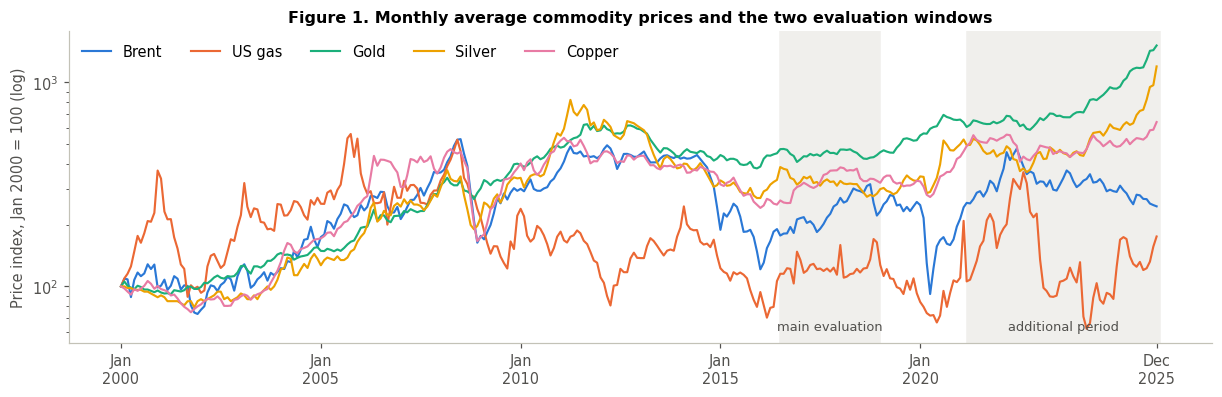

In [4]:
summary = pd.DataFrame({"mean, % p.a.": 100 * ret.mean() * 12, "volatility, % p.a.": 100 * ret.std() * np.sqrt(12),
                        "worst month, %": 100 * ret.min(), "autocorr. lag 1": ret.apply(lambda s: s.autocorr(1)),
                        "autocorr. lag 2": ret.apply(lambda s: s.autocorr(2))})
print("Table 1a. Simple monthly price changes, Feb 2000 - Dec 2025 (311 observations)")
show(summary)
print("Table 1b. Correlations of monthly log price changes, same period")
show(log_ret.corr())

fig, ax = plt.subplots(figsize=(11, 3.5), layout="constrained")
for (name, s), color in zip((100 * prices / prices.iloc[0]).items(), ASSET_COLORS):
    ax.plot(s.index, s, color=color, lw=1.4, label=name)
for lo, hi, tag in [("2016-07-01", "2018-12-31", "main evaluation"), ("2021-03-01", "2025-12-31", "additional period")]:
    ax.axvspan(pd.Timestamp(lo), pd.Timestamp(hi), color="#f0efec", zorder=0)
    ax.text(pd.Timestamp(lo) + (pd.Timestamp(hi) - pd.Timestamp(lo)) / 2, 0.04, tag, ha="center", fontsize=8.5,
            color="#52514e", transform=ax.get_xaxis_transform())
ax.set(yscale="log", ylabel="Price index, Jan 2000 = 100 (log)",
       title="Figure 1. Monthly average commodity prices and the two evaluation windows")
ax.set_xticks(pd.to_datetime(["2000-01-01", "2005-01-01", "2010-01-01", "2015-01-01", "2020-01-01", "2025-12-01"]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax.legend(ncol=5, loc="upper left")
plt.show()

Gold has the lowest full-sample volatility (13% a year, against 21–54% for the other commodities) and a high average return. This helps contextualise the gold-heavy allocations below; actual weights depend on lagged conditional means and the full covariance matrix. Gold and silver are strongly correlated (0.75), while US gas has low correlations with the other assets. Positive lag-1 autocorrelations are consistent with monthly averaging (Section 3.1), although this descriptive table does not identify their cause. The windows differ substantially: gold is comparatively flat in 2016–2018, while 2021–2025 includes large energy-price swings and a sustained rise in precious-metal prices.


Label shares: positive 41.3%, negative 36.0%, neutral 3.7%, none 19.0% | headlines per month 14-250 (median 44) | describing past moves: 96.7%, looking ahead: 3.3%
Monthly sentiment S_t: mean 0.073, sd 0.206, range -0.38 to 0.53; correlation with the same month's gold change 0.43


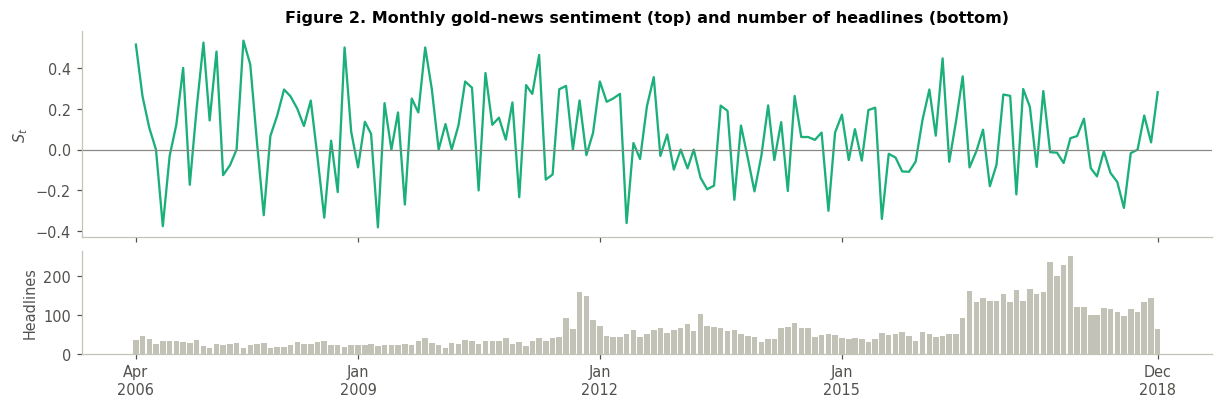

In [5]:
share = label_counts.sum() / label_counts.sum().sum()
print("Label shares: " + ", ".join(f"{k} {v:.1%}" for k, v in share.items())
      + f" | headlines per month {headlines.min()}-{headlines.max()} (median {headlines.median():.0f})"
      + f" | describing past moves: {news['Past Information'].mean():.1%}, looking ahead: {news['Future Information'].mean():.1%}")
print(f"Monthly sentiment S_t: mean {sentiment.mean():.3f}, sd {sentiment.std():.3f}, range {sentiment.min():.2f} to {sentiment.max():.2f}; "
      f"correlation with the same month's gold change {sentiment.corr(ret.Gold.reindex(sentiment.index)):.2f}")

fig, ax = plt.subplots(2, 1, figsize=(11, 3.6), sharex=True, layout="constrained", height_ratios=[2, 1])
ax[0].plot(sentiment.index, sentiment, color=OTHER_COLOR["News only"])
ax[0].axhline(0, color="#898781", lw=0.8)
ax[0].set(ylabel="$S_t$", title="Figure 2. Monthly gold-news sentiment (top) and number of headlines (bottom)")
ax[1].bar(headlines.index, headlines, width=25, color="#c3c2b7")
ax[1].set(ylabel="Headlines")
ax[1].set_xticks(pd.to_datetime(["2006-04-01", "2009-01-01", "2012-01-01", "2015-01-01", "2018-12-01"]))
ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
plt.show()

Positive and negative labels dominate (41% and 36%), and 19% of headlines carry no price direction. Coverage is uneven, from 14 to 250 headlines a month, with many more in 2016–2017, so sparse months may be more sensitive to individual headlines. For H2, 97% of headlines carry a past-information flag, and $S_t$ has a correlation of 0.43 with gold's change in the same month. Sentiment may therefore mostly repeat what prices already show. Section 4.3 examines linear lead–lag correlations and the sentiment-conditioned allocation.

## 3. Methodology and experimental design

### 3.1 Experimental protocol

Models are selected and fitted on past data only, then **frozen**. Portfolios are then rebuilt every month, walking forward through the evaluation period:

| | Main experiment (A) | Additional period (B) |
|:--|:--|:--|
| Training / validation | Apr 2006 – Dec 2012 / Jan 2013 – Dec 2015 | Apr 2006 – Dec 2015 / Jan 2016 – Dec 2020 |
| Models frozen at | Dec 2015 | Dec 2020 |
| Portfolio evaluation | Jul 2016 – Dec 2018 (30 months) | Mar 2021 – Dec 2025 (58 months) |
| Questions | H1, H2, H3, FRED | H1, FRED |

The two periods are separate experiments, and their results are never pooled.

**Information lag.** The decision for month $t$ uses data up to month $c=t-2$ only. Month $c$'s average is published early in month $c+1$, so this leaves time for publication and collection. It also matters for a statistical reason. Changes in monthly *averages* are autocorrelated at lag 1 even for a random walk (Working, 1960; see Table 1). A one-month lag can therefore introduce mechanical predictability: adjacent changes in averages share within-month price innovations. The two-month lag avoids this particular overlap; it does not make the price proxies executable. Evaluation starts in July 2016 (rather than January) because the first decision needs 120 past returns, each paired with a regime observed two months earlier, all after April 2006. Evaluation B starts in March 2021, the first month whose information cut-off (January 2021) falls after the models are frozen.

**Preventing look-ahead.** Scalers, cluster models, the number of states and the sentiment threshold use only training or development data. Features use backward-looking windows only. Portfolio settings are inherited from the earlier notebooks and held fixed in this comparison, without evaluation-Sharpe tuning. Both evaluation windows were previously examined during the project, so chronological separation does not make this a new confirmatory holdout. Section 3.5 checks computational timing.

In [6]:
EXPERIMENTS = {
    "A": dict(train_end="2012-12-01", model_end="2015-12-01", first="2016-07-01", last="2018-12-01",
              feature_sets=["price", "price+FRED", "price+news", "price+FRED+news"]),
    "B": dict(train_end="2015-12-01", model_end="2020-12-01", first="2021-03-01", last="2025-12-01",
              feature_sets=["price", "price+FRED"]),
}
for cfg in EXPERIMENTS.values():
    for key in ["train_end", "model_end", "first", "last"]:
        cfg[key] = pd.Timestamp(cfg[key])
    cfg["dates"] = pd.date_range(cfg["first"], cfg["last"], freq="MS")
    cfg["signals"] = cfg["dates"] - pd.DateOffset(months=LAG)    # information cut-off of each decision

### 3.2 Market regime detection

Regimes are found by **clustering months** on standardised features. No "true regime" label exists, so this is unsupervised learning, and it differs from classification: the clusters are only useful if they line up with differences in later returns or risk, which is what the portfolio test checks.

* **KMeans** assigns each month to its nearest centroid, so a month belongs to exactly one state.
* **GMM** fits a mixture of Gaussians with diagonal covariances and returns membership probabilities $p_{t,j}$. A month can therefore lie between two states.

**Scaling and selection.** For each feature set, $k\in\{2,3,4\}$ is fixed before any portfolio is evaluated. The scaler and the candidate models are fitted on training months. KMeans takes the $k$ with the highest **silhouette on validation months**, and the GMM the $k$ with the lowest **BIC on training months**. Both are then refitted on all development months (training plus validation) and frozen. States are numbered from the weakest (0) to the strongest membership-weighted mean of the five commodity log changes in the development sample. This is only for readability and does not affect any portfolio.

**What is compared.** Each feature set selects its own $k$. The main comparisons therefore evaluate the same selection-and-allocation procedure with different inputs; when selected counts differ, they do not isolate a feature at fixed model complexity. Section 5.1 separately reports the fixed-$k=3$ FRED–KMeans comparison used in Notebook 05. Neither specification is selected using evaluation Sharpe. BIC is compared only across $k$ within a feature set, not across feature spaces. Silhouette and BIC measure geometric separation and fit, respectively, rather than portfolio value; serially dependent monthly features further limit their interpretation.

**Interpretation and stability.** We describe each state with development-sample averages. We measure stability with the adjusted Rand index (ARI, where 1 means identical partitions up to relabelling) across random seeds, between the two algorithms, and between the two experiments' fits.

In [7]:
market_move = log_ret.mean(axis=1)            # descriptive index and state ordering; never a selection criterion

def make_model(alg, k, n_init, seed=SEED):
    if alg == "KMeans":
        return KMeans(n_clusters=k, n_init=n_init, random_state=seed)
    return GaussianMixture(n_components=k, covariance_type="diag", reg_covar=1e-4, n_init=n_init, max_iter=500, random_state=seed)

def select_k(X, train, valid):
    """KMeans: best validation silhouette. GMM: lowest training BIC. Scaler fitted on training months only."""
    scaler = StandardScaler().fit(X.loc[train])
    z_train, z_valid = scaler.transform(X.loc[train]), scaler.transform(X.loc[valid])
    rows = []
    for k in K_GRID:
        groups = make_model("KMeans", k, 30).fit(z_train).predict(z_valid)
        gmm = make_model("GMM", k, 10).fit(z_train)
        assert gmm.converged_
        n_groups = len(np.unique(groups))
        rows.append({"k": k, "silhouette": silhouette_score(z_valid, groups) if 1 < n_groups < len(groups) else np.nan,
                     "groups": n_groups, "BIC": gmm.bic(z_train)})
    table = pd.DataFrame(rows).set_index("k")
    assert table.silhouette.notna().any(), "No admissible validation silhouette"
    return {"KMeans": int(table.silhouette.idxmax()), "GMM": int(table.BIC.idxmin())}, table

def fit_regimes(X, alg, k, dev, seed=SEED):
    """Fit scaler and model on development months; return state memberships for every month, states ordered by return."""
    scaler = StandardScaler().fit(X.loc[dev])
    model = make_model(alg, k, 50 if alg == "KMeans" else 20, seed).fit(scaler.transform(X.loc[dev]))
    if alg == "GMM":
        assert model.converged_
    z = scaler.transform(X)
    p = pd.DataFrame(np.eye(k)[model.predict(z)] if alg == "KMeans" else model.predict_proba(z), index=X.index)
    w = p.loc[dev]
    p = p[(w.mul(market_move.loc[dev], axis=0).sum() / w.sum()).sort_values().index]
    p.columns = range(k)
    return p

def hard(p):
    return pd.Series(p.to_numpy().argmax(axis=1), index=p.index)

regimes, selection, chosen_k = {}, {}, {}
for exp, cfg in EXPERIMENTS.items():
    for fs in cfg["feature_sets"]:
        X = FEATURES[fs].loc[:cfg["last"]]
        train = X.index[X.index <= cfg["train_end"]]
        valid = X.index[(X.index > cfg["train_end"]) & (X.index <= cfg["model_end"])]
        dev = X.index[X.index <= cfg["model_end"]]
        chosen, selection[(exp, fs)] = select_k(X, train, valid)
        for alg in ["KMeans", "GMM"]:
            chosen_k[(exp, alg, fs)] = chosen[alg]
            regimes[(exp, alg, fs)] = fit_regimes(X, alg, chosen[alg], dev)

### 3.3 News sentiment

$S_t$ (Section 2.2) measures the balance of positive and negative gold-price headlines in month $t$. Because most headlines carry a past-information flag (Section 2.3), we treat it as a measure of recent market tone rather than as a forecast. Sentiment enters the allocation in two ways:

* **Sentiment-only (H2).** Two states: $S_t$ above or below its development-sample median (Apr 2006 – Dec 2015), fixed before the evaluation. The states then condition Markowitz exactly like KMeans regimes.
* **Combined (H3).** $S_t$ is added as an extra clustering feature, so KMeans and the GMM see the price features plus sentiment ("price+news"), or the price, FRED and sentiment features ("price+FRED+news"). The number of states is selected with the same rule as for every other feature set.

In [8]:
news_threshold = sentiment.loc[:EXPERIMENTS["A"]["model_end"]].median()
news_states = pd.DataFrame(np.eye(2)[(sentiment > news_threshold).astype(int)], index=sentiment.index)
print(f"Sentiment threshold (development median): {news_threshold:.3f}")

Sentiment threshold (development median): 0.081


### 3.4 Portfolio construction

At each decision month $t$ (cut-off $c=t-2$), every strategy uses the same window of 120 monthly returns $r_u$, $u=c-119,\dots,c$.

* **Equal weight:** 20% per asset, rebalanced monthly. No estimation.
* **Classical Markowitz:** empirical mean $\mu_0$ and population-normalised covariance $\Sigma_0$ of the window (divisor 120, not 119).
* **Regime-, sentiment- and combined-conditioned Markowitz.** These three differ only in the membership vectors $p$ they use. Each past return $r_u$ is paired with membership $p_{u-2}$ for the feature month two months earlier. Development memberships are retrospective classifications by the frozen model, which is available by every evaluation decision. For each state $j$ we compute population-normalised moments weighted by $a_{u,j}=p_{u-2,j}$, with effective sample size $n_j=(\sum_u a_{u,j})^2/\sum_u a_{u,j}^2$. When $n_j<12$, the state uses the unconditional moments $(\mu_0,\Sigma_0)$. Otherwise, the conditional **mean and raw second moment** are blended with their unconditional counterparts using weight $\alpha_j=n_j/(n_j+24)$ on the state estimate. Subtracting the blended mean outer product recovers $\Sigma_j$ and retains the between-mean dispersion. Small states are thus regularised, not discarded. The state moments are then mixed with the current membership $p_c$:
$$\mu=\sum_j p_{c,j}\,\mu_j,\qquad \Sigma=\sum_j p_{c,j}\left(\Sigma_j+\mu_j\mu_j^\top\right)-\mu\mu^\top ,$$
which keeps the spread between state means in the covariance.

**Risk estimation, constraints and costs.** For every optimised strategy, we halve the mean, $\hat\mu=0.5\mu$, use $\hat\Sigma=0.8\Sigma+0.2\operatorname{diag}(\Sigma)+10^{-8}I$, and solve
$$\max_w\; w^\top\hat\mu-\tfrac{\gamma}{2}\,w^\top\hat\Sigma w\quad\text{s.t.}\quad \mathbf 1^\top w=1,\; 0\le w_i\le 0.6,\qquad \gamma=5 .$$
These settings come from Notebook 02 and are held fixed here. This is constrained mean–variance utility maximisation, not direct Sharpe maximisation; $\gamma$ is the inverse of the course textbook's risk-tolerance parameter. Between rebalances, weights drift with returns: $\tilde w_{i,t}=w_{i,t-1}(1+r_{i,t-1})/(1+w_{t-1}^\top r_{t-1})$. Turnover is $TO_t=\sum_i|w_{i,t}-\tilde w_{i,t}|$, counting both buys and sells, and the first month starts from cash. The net return is
$$R_t=(1-0.001\,TO_t)(1+w_t^\top r_t)-1,$$
i.e. 10 bp per unit of two-sided turnover (20 bp per unit if the same turnover is divided by two). This is the project's stylised fee accounting, distinct from the course's quadratic impact-cost model. Costs are applied after weight selection and are not optimised.

In [9]:
def moments(R, a=None):
    p = np.full(len(R), 1 / len(R)) if a is None else a / a.sum()
    mu = p @ R
    centred = R - mu
    return mu, (centred * p[:, None]).T @ centred

def regularise(mu, cov):
    cov = (1 - COV_SHRINK) * cov + COV_SHRINK * np.diag(np.diag(cov))
    return (1 - MEAN_SHRINK) * mu, (cov + cov.T) / 2 + 1e-8 * np.eye(len(mu))

def optimise(mu, cov):
    n = len(mu)
    res = minimize(lambda w: GAMMA / 2 * w @ cov @ w - w @ mu, np.full(n, 1 / n), jac=lambda w: GAMMA * cov @ w - mu,
                   method="SLSQP", bounds=[(0, CAP)] * n, options={"ftol": 1e-12, "maxiter": 500},
                   constraints={"type": "eq", "fun": lambda w: w.sum() - 1, "jac": lambda w: np.ones(n)})
    if not res.success:
        raise RuntimeError(res.message)
    return res.x

def regime_moments(R, p_hist, p_now):
    """State-conditional moments shrunk towards the window's unconditional moments, mixed by current membership."""
    mu0, cov0 = moments(R)
    means, seconds = [], []
    for a in p_hist.T:
        n_eff = a.sum() ** 2 / (a @ a) if a @ a > 0 else 0.0
        if n_eff < MIN_EFFECTIVE:
            mu_j, second_j = mu0, cov0 + np.outer(mu0, mu0)
        else:
            mu_c, cov_c = moments(R, a)
            alpha = n_eff / (n_eff + PRIOR)
            mu_j = alpha * mu_c + (1 - alpha) * mu0
            second_j = alpha * (cov_c + np.outer(mu_c, mu_c)) + (1 - alpha) * (cov0 + np.outer(mu0, mu0))
        means.append(mu_j)
        seconds.append(second_j)
    mu = p_now @ np.array(means)
    return mu, np.tensordot(p_now, np.array(seconds), axes=1) - np.outer(mu, mu)

def allocate(memberships, dates, model_end, returns=ret):
    """Walk-forward target weights. Only data up to c = t - LAG enters the decision for month t."""
    W = {name: [] for name in ["Equal weight", "Markowitz", *memberships]}
    for t in dates:
        c = t - pd.DateOffset(months=LAG)
        hist = returns.loc[:c].tail(LOOKBACK)
        assert c > model_end and len(hist) == LOOKBACK and hist.index[-1] == c
        R, past_signals = hist.to_numpy(), hist.index - pd.DateOffset(months=LAG)   # r_u is paired with the state at u-2
        W["Equal weight"].append(np.full(R.shape[1], 1 / R.shape[1]))
        W["Markowitz"].append(optimise(*regularise(*moments(R))))
        for name, p in memberships.items():
            W[name].append(optimise(*regularise(*regime_moments(R, p.loc[past_signals].to_numpy(), p.loc[c].to_numpy()))))
    W = {k: pd.DataFrame(v, index=dates, columns=returns.columns) for k, v in W.items()}
    for w in W.values():
        assert np.allclose(w.sum(axis=1), 1) and w.min().min() > -1e-8 and w.max().max() < CAP + 1e-8
    return W

def backtest(w, fee_bps=FEE_BPS):
    held, rows = np.zeros(w.shape[1]), []
    for t, target in w.iterrows():
        r = ret.loc[t].to_numpy()
        turnover = np.abs(target.to_numpy() - held).sum()
        gross = target.to_numpy() @ r
        rows.append((gross, (1 - fee_bps / 1e4 * turnover) * (1 + gross) - 1, turnover))
        held = target.to_numpy() * (1 + r) / (1 + gross)        # drifted weights before the next rebalance
    return pd.DataFrame(rows, index=w.index, columns=["gross", "net", "turnover"])

### 3.5 Evaluation

We report net CAGR, volatility $\sqrt{12}\,s_R$, maximum drawdown (including initial wealth one), turnover, mean gold weight, and $SR=\sqrt{12}\,\bar R/s_R$ with a zero risk-free rate. The square-root-of-12 scaling is a reporting convention for monthly returns, not an estimate of the Sharpe ratio of annual compounded returns under serial dependence. With $SR_m=\bar R/s_R$, Lo's (2002) **IID-normal approximation**, $\mathrm{SE}(SR)\approx\sqrt{12(1+SR_m^2/2)/T}$, gives about 0.63 in A and 0.46–0.47 in B. It is an uncertainty benchmark, not a dependence-robust standard error.

The main evidence uses **paired differences** under the common experimental conditions. A circular block bootstrap draws the same months for both strategies: 1,000 resamples of six-month blocks, with 2.5th and 97.5th percentiles forming an approximate 95% interval. This preserves cross-strategy dependence and some serial dependence. It conditions on the fitted models and realised allocation paths, without repeating estimation or selection; only 5–10 blocks enter each resample. The 19 summary contrasts, benchmark comparisons and sensitivity checks are exploratory and unadjusted for multiple comparisons. Isolated exclusions of zero are therefore insufficient for a confirmatory claim.

The next cells check (1) invariance of allocations when returns and memberships after each cutoff are perturbed, (2) price-feature agreement under truncated histories, and (3) independent reconciliation of net returns. These checks address computational timing and accounting, not historical data availability.


In [10]:
STRATEGY_ORDER = ["Equal weight", "Markowitz"] + [f"{a} · {f}" for f in ["price", "price+FRED"] for a in ["KMeans", "GMM"]] \
                 + ["News only"] + [f"{a} · {f}" for f in ["price+news", "price+FRED+news"] for a in ["KMeans", "GMM"]]

def memberships(exp):
    m = {f"{alg} · {fs}": regimes[(exp, alg, fs)] for fs in EXPERIMENTS[exp]["feature_sets"] for alg in ["KMeans", "GMM"]}
    if exp == "A":
        m["News only"] = news_states
    return m

results = {}
for exp, cfg in EXPERIMENTS.items():
    W = allocate(memberships(exp), cfg["dates"], cfg["model_end"])
    order = [s for s in STRATEGY_ORDER if s in W]
    paths = {s: backtest(W[s]) for s in order}
    results[exp] = dict(weights={s: W[s] for s in order}, paths=paths, net=pd.DataFrame({s: paths[s].net for s in order}))

def sharpe(x):
    return np.sqrt(12) * x.mean() / x.std(ddof=1)

def performance(exp):
    rows = {}
    for s, path in results[exp]["paths"].items():
        wealth, sr, T = np.r_[1.0, (1 + path.net).cumprod()], sharpe(path.net), len(path)
        rows[s] = {"Sharpe": sr, "SE (IID)": np.sqrt(12 * (1 + sr ** 2 / 24) / T), "CAGR": wealth[-1] ** (12 / T) - 1,
                   "volatility": path.net.std() * np.sqrt(12), "max drawdown": (wealth / np.maximum.accumulate(wealth) - 1).min(),
                   "turnover / month": path.turnover.mean(), "gold weight": results[exp]["weights"][s]["Gold"].mean()}
    return pd.DataFrame(rows).T

def contrasts(net, pairs, block=6, reps=1000, seed=SEED):
    """Paired circular block bootstrap of Sharpe-ratio differences (same resampled months for both strategies)."""
    n, rng = len(net), np.random.default_rng(seed)
    idx = np.stack([np.concatenate([(s + np.arange(block)) % n for s in rng.integers(0, n, int(np.ceil(n / block)))])[:n]
                    for _ in range(reps)])
    X = net.to_numpy()[idx]
    draws = pd.DataFrame(np.sqrt(12) * X.mean(axis=1) / X.std(axis=1, ddof=1), columns=net.columns)
    observed = sharpe(net)
    return pd.DataFrame({label: {"ΔSharpe": observed[a] - observed[b], "95% low": (draws[a] - draws[b]).quantile(0.025),
                                 "95% high": (draws[a] - draws[b]).quantile(0.975)} for label, (a, b) in pairs.items()}).T

perf = {exp: performance(exp) for exp in EXPERIMENTS}
PCT = {c: "{:.1%}" for c in ["CAGR", "volatility", "max drawdown", "turnover / month", "gold weight"]}

In [11]:
rng = np.random.default_rng(2026)
for exp, cfg in EXPERIMENTS.items():                                   # (1) no look-ahead in any decision
    for t in cfg["dates"]:
        c = t - pd.DateOffset(months=LAG)
        fake_ret = ret.copy()
        fake_ret.loc[fake_ret.index > c] = rng.uniform(-0.4, 0.5, size=((fake_ret.index > c).sum(), ret.shape[1]))
        fake = {}
        for s, p in memberships(exp).items():
            fake[s] = p.copy()
            fake[s].loc[p.index > c] = rng.dirichlet(np.ones(p.shape[1]), (p.index > c).sum())
        replay = allocate(fake, pd.DatetimeIndex([t]), cfg["model_end"], returns=fake_ret)
        for s in replay:
            np.testing.assert_allclose(replay[s].loc[t], results[exp]["weights"][s].loc[t], atol=1e-10)
for cut in ["2012-06-01", "2016-05-01", "2020-12-01"]:                 # (2) features are causal
    lr_cut = np.log(prices.loc[:cut]).diff().dropna()
    f_cut = pd.concat({"ret": lr_cut, "mom3": lr_cut.rolling(3).sum(), "vol12": lr_cut.rolling(12).std() * np.sqrt(12)}, axis=1)
    f_cut.columns = price_feat.columns
    pd.testing.assert_frame_equal(f_cut.loc[SAMPLE_START:], price_feat.loc[SAMPLE_START:cut])
for exp in EXPERIMENTS:                                                # (3) cash flows reconcile
    for s, w in results[exp]["weights"].items():
        r = ret.loc[w.index]
        gross = (w * r).sum(axis=1)
        drifted = (w * (1 + r)).div(1 + gross, axis=0).shift(1).fillna(0)
        net = (1 - FEE_BPS / 1e4 * (w - drifted).abs().sum(axis=1)) * (1 + gross) - 1
        np.testing.assert_allclose(results[exp]["net"][s], net, atol=1e-12)
print(f"PASS: allocation cutoff invariance in {sum(len(c['dates']) for c in EXPERIMENTS.values())} decision months, backward-looking price features, "
      "cash flows reconcile.")

PASS: allocation cutoff invariance in 88 decision months, backward-looking price features, cash flows reconcile.


## 4. Empirical results

### 4.1 Market regime identification

In [12]:
sel = pd.DataFrame({(exp, fs): {**{f"silhouette k={k}": "–" if np.isnan(t.loc[k, "silhouette"]) else
                                   f"{t.loc[k, 'silhouette']:.3f} ({t.loc[k, 'groups']})" for k in K_GRID},
                                **{f"BIC k={k}": f"{t.loc[k, 'BIC']:.0f}" for k in K_GRID},
                                "chosen k: KMeans / GMM": f"{chosen_k[(exp, 'KMeans', fs)]} / {chosen_k[(exp, 'GMM', fs)]}"}
                    for (exp, fs), t in selection.items()}).T.rename_axis(["experiment", "features"])
print("Table 2. Model selection. KMeans: validation silhouette (clusters actually used by the validation months). GMM: training BIC.")
display(sel)

Table 2. Model selection. KMeans: validation silhouette (clusters actually used by the validation months). GMM: training BIC.


silhouette k=2 silhouette k=3 silhouette k=4  \
experiment features                                                       
A          price                0.070 (2)      0.171 (2)      0.170 (2)   
           price+FRED           0.162 (2)      0.173 (2)              –   
           price+news           0.043 (2)      0.161 (2)      0.152 (2)   
           price+FRED+news      0.164 (2)              –              –   
B          price                0.154 (2)      0.286 (3)      0.145 (4)   
           price+FRED           0.159 (2)      0.219 (3)      0.254 (3)   

                           BIC k=2 BIC k=3 BIC k=4 chosen k: KMeans / GMM  
experiment features                                                        
A          price              3297    3290    3242                  3 / 4  
           price+FRED         4654    4448    4443                  3 / 4  
           price+news         3543    3532    3494                  3 / 4  
           price+FRED+news    4899    4829    4688                  2 / 4  
B          price              4809    4591    4590                  3 / 4  
           price+FRED         6759    6407    6231                  4 / 4

Validation silhouettes range from 0.04 to 0.29, indicating weak separation by average within- and between-cluster distances. In A, validation months occupy at most two KMeans clusters. With price+FRED+news, all validation months are assigned to a single cluster at $k=3$ or 4; the training clusters have not disappeared, but the validation silhouette is undefined. The rule therefore selects $k=2$ for this feature set, versus $k=3$ without news. Price-only and price+news both select $k=3$.

Some scores nearly tie (0.171 versus 0.170 for price-only KMeans). GMM BIC decreases throughout the grid and selects its upper boundary, $k=4$, for every feature set. These rules are defensible descriptions of fit, but do not identify a uniquely supported economic regime count. The sensitivity analysis retains all three counts without choosing the most profitable one.


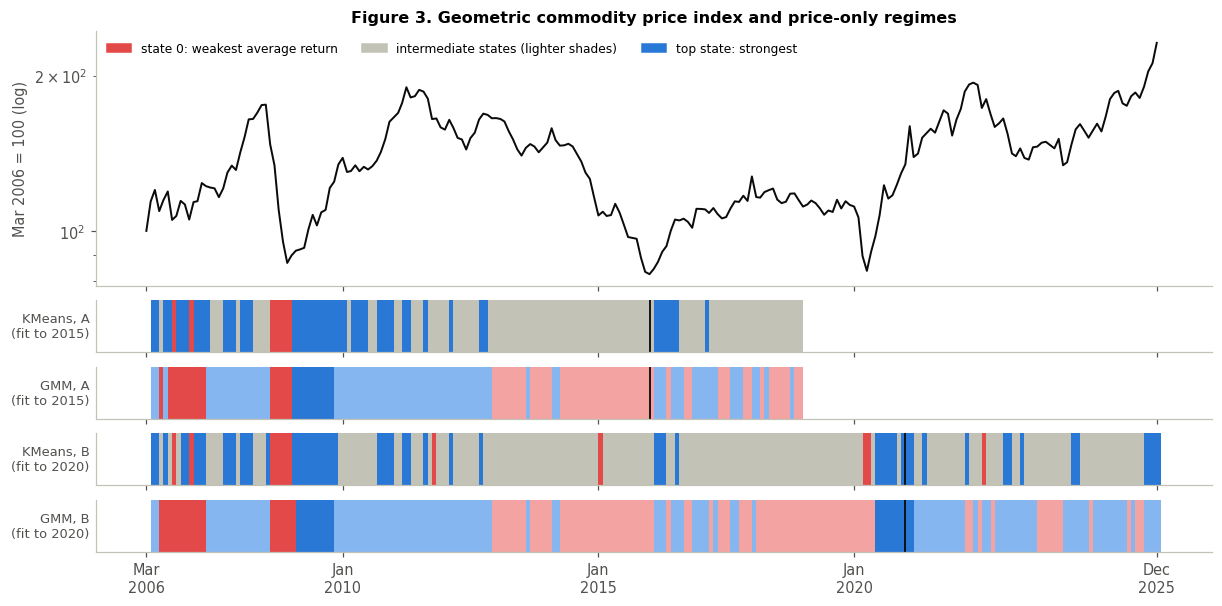

Do the regimes survive five more years of data? ARI between the A fit (to 2015) and the B fit (to 2020) on Apr 2006 - Dec 2015: KMeans 0.64, GMM 0.97


In [13]:
STATE_COLORS = {2: ["#e34948", "#2a78d6"], 3: ["#e34948", "#c3c2b7", "#2a78d6"], 4: ["#e34948", "#f2a3a2", "#86b6ef", "#2a78d6"]}
strips = [(e, a) for e in ["A", "B"] for a in ["KMeans", "GMM"]]
base_month = SAMPLE_START - pd.DateOffset(months=1)
basket = pd.concat([pd.Series({base_month: 100.0}), 100 * np.exp(market_move.loc[SAMPLE_START:].cumsum())])
fig, axes = plt.subplots(1 + len(strips), 1, figsize=(11, 5.4), sharex=True, layout="constrained",
                         height_ratios=[2.2] + [0.45] * len(strips))
axes[0].plot(basket.index, basket, color="#0b0b0b", lw=1.3)
axes[0].set(ylabel="Mar 2006 = 100 (log)", yscale="log", title="Figure 3. Geometric commodity price index and price-only regimes")
for ax, (exp, alg) in zip(axes[1:], strips):
    p = regimes[(exp, alg, "price")]
    edges = np.append(mdates.date2num(p.index), mdates.date2num(p.index[-1] + pd.DateOffset(months=1)))
    for i, s in enumerate(hard(p)):
        ax.axvspan(edges[i], edges[i + 1], color=STATE_COLORS[p.shape[1]][s], lw=0)
    ax.axvline(EXPERIMENTS[exp]["model_end"] + pd.DateOffset(months=1), color="#0b0b0b", lw=1.2, ls="-")
    ax.set_yticks([]); ax.grid(False)
    ax.set_ylabel(f"{alg}, {exp}\n(fit to {EXPERIMENTS[exp]['model_end']:%Y})", rotation=0, ha="right", va="center", fontsize=8.5)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in ["#e34948", "#c3c2b7", "#2a78d6"]]
axes[0].legend(handles, ["state 0: weakest average return", "intermediate states (lighter shades)", "top state: strongest"],
               ncol=3, loc="upper left", fontsize=8)
axes[-1].set_xticks(pd.to_datetime(["2006-03-01", "2010-01-01", "2015-01-01", "2020-01-01", "2025-12-01"]))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
plt.show()
overlap = pd.date_range(SAMPLE_START, EXPERIMENTS["A"]["model_end"], freq="MS")
print("Do the regimes survive five more years of data? ARI between the A fit (to 2015) and the B fit (to 2020) on Apr 2006 - Dec 2015: "
      + ", ".join(f"{a} {adjusted_rand_score(hard(regimes[('A', a, 'price')]).loc[overlap], hard(regimes[('B', a, 'price')]).loc[overlap]):.2f}"
                  for a in ["KMeans", "GMM"]))

The index is $I_t=100\exp(\sum_{u=\mathrm{Apr\ 2006}}^t \frac15\sum_i\ell_{i,u})$, with March 2006 as its base. It summarises prices geometrically; a monthly rebalanced equal-weight portfolio instead compounds $1+\frac15\sum_i r_{i,t}$. Solid vertical markers separate development labels from later assignments.

Both algorithms assign the late-2008 collapse to their weakest state and most of the 2009–2010 recovery to their strongest. KMeans concentrates calmer months in a middle state; GMM splits these further. Adding five years of fitting data changes the price-only GMM partition little (ARI 0.97 on 2006–2015), but KMeans more (0.64). In A, KMeans uses its middle state for 26 of 30 signals; GMM alternates between two intermediate hard states while retaining all four soft memberships (Table 4).


In [14]:
profile_vars = pd.DataFrame({"mean log change, %/m": 100 * market_move, "12m vol., % p.a.": 100 * price_feat.filter(like="vol12").mean(axis=1),
                             "VIX": fred.VIXCLS, "10y-2y slope, pp": macro_feat["10y-2y slope"],
                             "basket at t+2, %": 100 * ret.mean(axis=1).shift(-LAG)})

def state_profile(models, cols):
    rows = []
    for exp, alg, fs in models:
        cfg, p = EXPERIMENTS[exp], regimes[(exp, alg, fs)]
        lab = hard(p)
        dev, sig = lab.loc[:cfg["model_end"]], lab.loc[cfg["signals"]]
        for j in range(p.shape[1]):
            d, e = profile_vars.loc[dev.index[dev == j]], profile_vars.loc[sig.index[sig == j]]
            rows.append({"model": f"{exp}: {alg} · {fs}", "state": j, "dev. months": len(d), **d[cols].mean().to_dict(),
                         "forward %, dev. cohort": d["basket at t+2, %"].mean(), "eval. months": len(e),
                         "forward %, eval. cohort": e["basket at t+2, %"].mean()})
    return pd.DataFrame(rows).set_index(["model", "state"])

print("Table 3. Price-only state profiles and ex-post forward simple returns (equal-weight basket); volatility is mean asset volatility")
show(state_profile([(e, a, "price") for e, a in strips], ["mean log change, %/m", "12m vol., % p.a.", "VIX"]),
     **{"dev. months": "{:.0f}", "eval. months": "{:.0f}", "VIX": "{:.1f}"})

Table 3. Price-only state profiles and ex-post forward simple returns (equal-weight basket); volatility is mean asset volatility


dev. months mean log change, %/m 12m vol., % p.a.  \
model             state                                                     
A: KMeans · price 0               7               -12.87            36.69   
                  1              66                -1.61            21.91   
                  2              44                 4.05            31.65   
A: GMM · price    0              15                -4.83            36.85   
                  1              34                -2.20            19.97   
                  2              58                 1.64            25.05   
                  3              10                 3.35            41.15   
B: KMeans · price 0              11               -11.93            32.60   
                  1             121                -0.39            23.09   
                  2              45                 4.53            31.78   
B: GMM · price    0              17                -3.78            37.09   
                  1              73                -1.55            21.22   
                  2              71                 1.94            24.97   
                  3              16                 4.07            39.40   

                          VIX forward %, dev. cohort eval. months  \
model             state                                             
A: KMeans · price 0      35.8                  -3.38            0   
                  1      17.8                  -0.43           26   
                  2      22.4                   1.34            4   
A: GMM · price    0      23.5                  -0.67            0   
                  1      15.1                  -1.61           14   
                  2      20.9                   0.47           16   
                  3      33.5                   4.43            0   
B: KMeans · price 0      36.5                  -1.08            1   
                  1      16.7                  -0.04           46   
                  2      23.2                   2.56           11   
B: GMM · price    0      24.3                  -1.19            0   
                  1      16.3                  -0.37           14   
                  2      19.6                   0.77           42   
                  3      29.7                   5.73            2   

                        forward %, eval. cohort  
model             state                          
A: KMeans · price 0                           –  
                  1                        0.54  
                  2                        2.01  
A: GMM · price    0                           –  
                  1                        1.85  
                  2                       -0.23  
                  3                           –  
B: KMeans · price 0                       -6.40  
                  1                        1.60  
                  2                       -0.02  
B: GMM · price    0                           –  
                  1                        1.44  
                  2                        1.31  
                  3                       -4.15

**Reading Table 3.** Forward returns are descriptive ex-post averages grouped by signal month; they are not used for fitting or selection. The development signal cohort ends in December 2015 (A) or December 2020 (B), so its final outcomes extend to February 2016 or February 2021. The allocation estimator instead uses only outcomes dated at or before each decision cutoff. GMM profiles use hard assignments; portfolios use soft memberships.

KMeans identifies a rare sell-off state (mean log change about −12% a month, VIX near 36), a large calm state and a rally state. Its development-cohort forward returns rise with the state: approximately +1.3% (A) and +2.6% (B) after rallies, versus −3.4% and −1.1% after sell-offs. GMM's ordering is less regular.

The ordering does not persist reliably. In A, KMeans rally signals precede +2.0% versus +0.5% after calm signals, but there are only four rally observations. GMM's two occupied states reverse their development ordering. In B, KMeans rally signals precede a flat basket versus +1.6% after calm signals. These small retrospective groups do not establish predictable returns.


In [15]:
diag_rows = []
for (exp, alg, fs), p in regimes.items():
    cfg = EXPERIMENTS[exp]
    X = FEATURES[fs].loc[:cfg["last"]]
    dev = X.index[X.index <= cfg["model_end"]]
    lab, k = hard(p), p.shape[1]
    sig = lab.loc[cfg["signals"]]
    seeds = [adjusted_rand_score(lab.loc[dev], hard(fit_regimes(X, alg, k, dev, seed)).loc[dev]) for seed in [0, 7, 21, 99]]
    other = hard(regimes[(exp, "GMM" if alg == "KMeans" else "KMeans", fs)])
    diag_rows.append({"experiment": exp, "features": fs, "model": alg, "k": k,
                      "dev. months per state": ", ".join(str(int((lab.loc[dev] == j).sum())) for j in range(k)),
                      "eval. months per state": ", ".join(str(int((sig == j).sum())) for j in range(k)),
                      "persistence": (sig.values[1:] == sig.values[:-1]).mean(),
                      "top membership": p.loc[cfg["signals"]].max(axis=1).mean(),
                      "KMeans-GMM ARI": adjusted_rand_score(lab.loc[dev], other.loc[dev]),
                      "seed ARI (min)": min(seeds)})
diagnostics = pd.DataFrame(diag_rows).set_index(["experiment", "features", "model"])
print("Table 4. Regime diagnostics for all twelve models. Persistence and top membership (mean of max_j p_tj) are measured on "
      "evaluation signals; ARIs on development months; seed ARI uses seeds 0, 7, 21, 99.")
show(diagnostics, k="{:.0f}")

Table 4. Regime diagnostics for all twelve models. Persistence and top membership (mean of max_j p_tj) are measured on evaluation signals; ARIs on development months; seed ARI uses seeds 0, 7, 21, 99.


k dev. months per state  \
experiment features        model                             
A          price           KMeans  3             7, 66, 44   
                           GMM     4        15, 34, 58, 10   
           price+FRED      KMeans  3             4, 62, 51   
                           GMM     4        53, 12, 12, 40   
           price+news      KMeans  3             7, 59, 51   
                           GMM     4        18, 27, 42, 30   
           price+FRED+news KMeans  2                61, 56   
                           GMM     4        52, 12, 12, 41   
B          price           KMeans  3           11, 121, 45   
                           GMM     4        17, 73, 71, 16   
           price+FRED      KMeans  4       18, 15, 102, 42   
                           GMM     4        20, 90, 17, 50   

                                  eval. months per state persistence  \
experiment features        model                                       
A          price           KMeans               0, 26, 4        0.90   
                           GMM              0, 14, 16, 0        0.62   
           price+FRED      KMeans               0, 26, 4        0.79   
                           GMM              18, 0, 0, 12        0.62   
           price+news      KMeans               0, 22, 8        0.76   
                           GMM              2, 0, 17, 11        0.52   
           price+FRED+news KMeans                  22, 8        0.69   
                           GMM              18, 0, 0, 12        0.62   
B          price           KMeans              1, 46, 11        0.75   
                           GMM              0, 14, 42, 2        0.74   
           price+FRED      KMeans           1, 20, 28, 9        0.60   
                           GMM              2, 23, 1, 32        0.65   

                                  top membership KMeans-GMM ARI seed ARI (min)  
experiment features        model                                                
A          price           KMeans           1.00           0.23           0.82  
                           GMM              0.91           0.23           0.40  
           price+FRED      KMeans           1.00           0.51           0.93  
                           GMM              0.93           0.51           0.63  
           price+news      KMeans           1.00           0.36           0.70  
                           GMM              0.91           0.36           0.27  
           price+FRED+news KMeans           1.00           0.49           1.00  
                           GMM              0.95           0.49           0.47  
B          price           KMeans           1.00           0.26           0.84  
                           GMM              0.93           0.26           0.48  
           price+FRED      KMeans           1.00           0.63           0.81  
                           GMM              0.93           0.63           0.92

* **Algorithm agreement:** development ARI is 0.23–0.63, lowest for price-only features. KMeans and GMM identify different partitions.
* **Seed sensitivity:** minimum ARI is 0.70–1.00 for KMeans and 0.27–0.92 for GMM. Several GMM fits are sensitive to initialisation despite convergence; the price-only refit agreement above is a separate diagnostic.
* **Soft memberships:** GMM's largest probability averages 0.91–0.95 in evaluation. Concentrated assignments are not calibrated confidence in a true economic state.
* **Sparse occupancy:** some KMeans states contain only 4–7 development months, and seven of eight A models leave a hard state unvisited in evaluation. Unconditional fallback depends on effective size in each rolling return window, not development occupancy alone.
* **Persistence:** adjacent signals retain their state 52–90% of the time; overlapping momentum and volatility windows may contribute.

These diagnostics support treating the clusters as rough descriptions of market conditions, rather than well-identified economic regimes.

### 4.2 H1: Do market regimes improve portfolio allocation?

We compare equal weight, Markowitz, and Markowitz conditioned on the price-only KMeans and GMM regimes in the main window. The additional period 2021–2025 is in Section 5.1, and regimes with FRED features in Section 4.5.

Table 5. H1, main window (Jul 2016 - Dec 2018, 30 months), net of 10 bp costs


,Sharpe,CAGR,volatility,max drawdown,turnover / month,gold weight,ΔSharpe vs Markowitz [95%]
Equal weight,0.64,8.2%,13.7%,-10.2%,7.3%,20.0%,"+0.30 [-0.36, +1.02]"
Markowitz,0.35,2.8%,9.2%,-11.3%,8.9%,60.0%,
KMeans · price,0.43,3.1%,7.9%,-11.8%,13.4%,59.4%,"+0.08 [-0.42, +0.74]"
GMM · price,0.57,5.4%,10.0%,-10.4%,24.7%,60.0%,"+0.23 [-0.29, +0.70]"


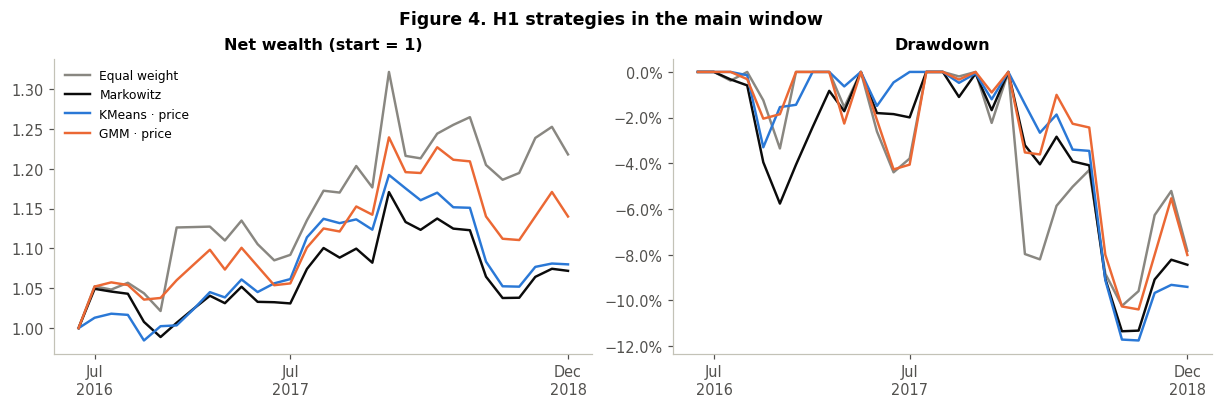

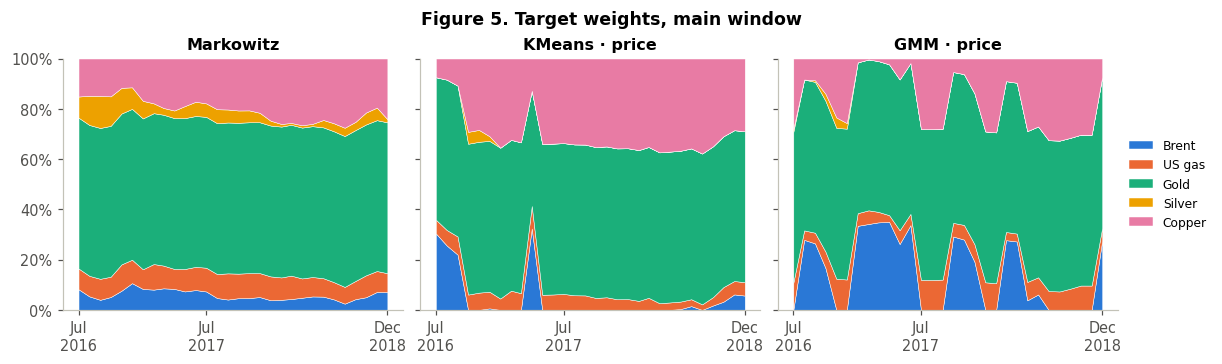

Table 6. Gross return difference with Markowitz by asset, % per year


,Brent,US gas,Gold,Silver,Copper,total
Equal weight,+1.6,+3.3,+0.1,-0.6,+1.1,+5.6
KMeans · price,-1.2,-0.7,-0.2,+0.2,+2.3,+0.3
GMM · price,+0.1,+0.8,-0.0,+0.3,+1.5,+2.7


In [16]:
H1 = ["Equal weight", "Markowitz", "KMeans · price", "GMM · price"]

def with_contrast(exp, names, base="Markowitz"):
    table = perf[exp].loc[names].drop(columns="SE (IID)").copy()
    c = contrasts(results[exp]["net"], {s: (s, base) for s in names if s != base})
    table[f"ΔSharpe vs {base} [95%]"] = [f"{c.loc[s, 'ΔSharpe']:+.2f} [{c.loc[s, '95% low']:+.2f}, {c.loc[s, '95% high']:+.2f}]"
                                       if s in c.index else "" for s in names]
    return table

print("Table 5. H1, main window (Jul 2016 - Dec 2018, 30 months), net of 10 bp costs")
show(with_contrast("A", H1), **PCT)

net, W = results["A"]["net"], results["A"]["weights"]
start = net.index[0] - pd.DateOffset(months=1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), layout="constrained")
for s in H1:
    wealth = pd.concat([pd.Series({start: 1.0}), (1 + net[s]).cumprod()])
    axes[0].plot(wealth.index, wealth, lw=1.6, label=s, **style(s))
    axes[1].plot(wealth.index, wealth / wealth.cummax() - 1, lw=1.6, label=s, **style(s))
axes[0].set(title="Net wealth (start = 1)")
axes[1].set(title="Drawdown")
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].legend(fontsize=8)
for ax in axes:
    ax.set_xticks(pd.to_datetime(["2016-07-01", "2017-07-01", "2018-12-01"]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
fig.suptitle("Figure 4. H1 strategies in the main window", fontweight="bold")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True, layout="constrained")
for ax, s in zip(axes, ["Markowitz", "KMeans · price", "GMM · price"]):
    ax.stackplot(W[s].index, W[s].T.to_numpy(), colors=ASSET_COLORS, labels=W[s].columns, edgecolor="white", linewidth=0.3)
    ax.set(title=s, ylim=(0, 1))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_xticks(pd.to_datetime(["2016-07-01", "2017-07-01", "2018-12-01"]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
fig.suptitle("Figure 5. Target weights, main window", fontweight="bold")
plt.show()

def attribution(exp, names, base="Markowitz"):
    """Annualised gross return gained or lost against the base, by asset: 12 x mean((w - w_base) * r), in %."""
    W, r = results[exp]["weights"], ret.loc[EXPERIMENTS[exp]["dates"]]
    out = pd.DataFrame({s: 100 * 12 * ((W[s] - W[base]) * r).mean() for s in names}).T
    out["total"] = out.sum(axis=1)
    return out

print("Table 6. Gross return difference with Markowitz by asset, % per year")
show(attribution("A", ["Equal weight", "KMeans · price", "GMM · price"]), "{:+.1f}")

Both regime strategies finish above Markowitz (Sharpe 0.43 and 0.57, against 0.35) but below equal weight (0.64), and both intervals include zero. Drawdowns are similar for all four strategies (−10% to −12%), all reached in the second half of 2018.

Figure 5 shows how the regimes change decisions. Markowitz and price-only GMM hold gold at 60% in all 30 months. Price-only KMeans averages 59.4%, reaches the cap in 27 months and falls to 45.8% at its minimum. Most allocation changes involve the other assets, but gold is not fixed for every strategy. Markowitz spreads that slice over copper, gas, Brent and silver and barely changes it. KMeans holds most of it in copper and occasionally switches a large part into Brent. The GMM moves Brent between 0 and about 35% from one month to the next. This is why regime turnover is 13–25% a month, against 9% for Markowitz.

Table 6 shows what these moves earned. Before costs, the GMM gained 2.7 points a year over Markowitz, mostly from copper (+1.5) and gas (+0.8). KMeans gained only 0.3 points: its copper gains (+2.3) were offset by losses on Brent (−1.2) and gas (−0.7). Equal weight did better than both (+5.6 points), simply by holding more gas and Brent, which Markowitz underweights.

**Conclusion for H1 (main window).** Conditioning on regimes changes the allocation visibly, but the performance difference cannot be distinguished from noise. The additional period (Section 5.1) does not support H1 either.

### 4.3 H2: Does news sentiment improve portfolio allocation?

Sentiment could help through conditional expected returns or risk at the two-month decision horizon. Linear return correlations are one diagnostic, not a complete test of that information. Figure 6 shows the correlation between $S_t$ and each commodity's change $r_{t+h}$, from three months before to three months after the news month. The solid reference lines mark $\pm1.96/\sqrt{153}$, an IID zero-correlation reference. They ignore serial dependence and multiple lag/asset comparisons, so they are not calibrated confidence bounds. This ex-post diagnostic uses news months April 2006–December 2018 and, at positive leads, outcomes through March 2019; it is not used for fitting or selection.

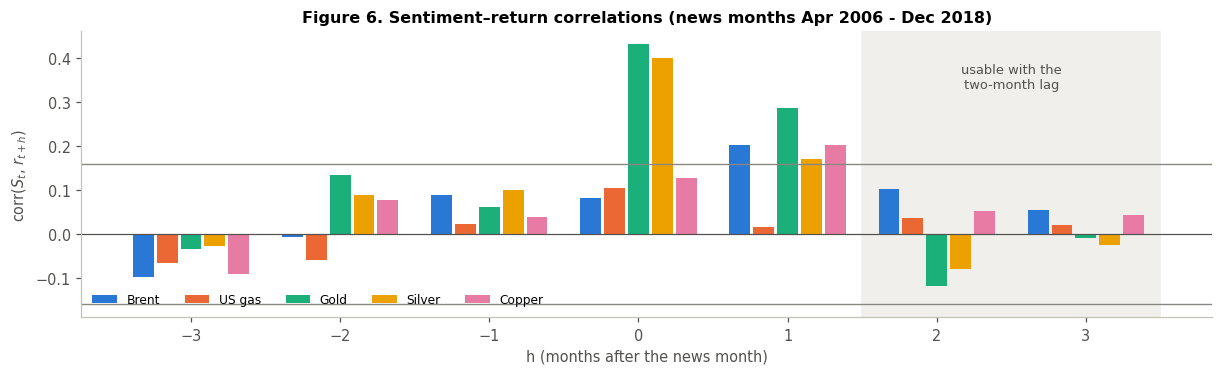

Table 7. H2, main window


,Sharpe,CAGR,volatility,max drawdown,turnover / month,gold weight,ΔSharpe vs Markowitz [95%]
Markowitz,0.35,2.8%,9.2%,-11.3%,8.9%,60.0%,
News only,0.20,1.5%,10.3%,-11.9%,27.6%,59.1%,"-0.15 [-0.49, +0.15]"


Evaluation signals in the high-sentiment state: 33%. Mean |weight difference| with Markowitz (pp): Brent 6.0, US gas 4.4, Gold 0.9, Silver 11.7, Copper 3.9


,Brent,US gas,Gold,Silver,Copper,total
News only,+0.3,-0.5,-0.1,+0.2,-0.7,-0.9


In [17]:
lead_lag = pd.DataFrame({h: {a: sentiment.corr(ret[a].shift(-h).reindex(sentiment.index)) for a in ret.columns}
                         for h in range(-3, 4)}).T
band = 1.96 / np.sqrt(len(sentiment))
fig, ax = plt.subplots(figsize=(11, 3.3), layout="constrained")
for i, (a, color) in enumerate(zip(ret.columns, ASSET_COLORS)):
    ax.bar(lead_lag.index + (i - 2) * 0.16, lead_lag[a], 0.14, color=color, label=a)
ax.axvspan(1.5, 3.5, color="#f0efec", zorder=0)
ax.text(2.5, 0.33, "usable with the\ntwo-month lag", ha="center", fontsize=8.5, color="#52514e")
for b in (band, -band):
    ax.axhline(b, color="#898781", lw=0.9, ls="-")
ax.axhline(0, color="#52514e", lw=0.8)
ax.set(xlabel="h (months after the news month)", ylabel="corr($S_t$, $r_{t+h}$)",
       title="Figure 6. Sentiment–return correlations (news months Apr 2006 - Dec 2018)")
ax.legend(ncol=5, fontsize=8, loc="lower left")
plt.show()

print("Table 7. H2, main window")
show(with_contrast("A", ["Markowitz", "News only"]), **PCT)
state_share = news_states.loc[EXPERIMENTS["A"]["signals"], 1].mean()
w_diff = 100 * (W["News only"] - W["Markowitz"])
print(f"Evaluation signals in the high-sentiment state: {state_share:.0%}. Mean |weight difference| with Markowitz (pp): "
      + ", ".join(f"{a} {v:.1f}" for a, v in w_diff.abs().mean().items()))
show(attribution("A", ["News only"]), "{:+.1f}")

Sentiment correlates with same-month gold and silver changes (0.43 and 0.40). Correlations at $h=1$ remain positive for gold (0.29), Brent and copper (both 0.20); temporal averaging may contribute, but this plot does not identify the mechanism. At $h=2,3$, all correlations lie within ±0.12. These are weak unconditional linear associations, not evidence that sentiment contains no predictive information about nonlinear effects, conditional means or risk.

The sentiment strategy changes silver and Brent weights most (mean absolute differences from Markowitz of 11.7 and 6.0 percentage points). Gold averages 59.1%, ranging from 52.6% to 60.0%. Monthly turnover rises from 8.9% to 27.6%, while the annualised gross return difference is −0.9 percentage points. Sample Sharpe falls from 0.35 to 0.20; the paired difference is −0.15 with interval [−0.49, +0.15].

**Conclusion for H2.** This sentiment definition and allocation rule do not demonstrate an improvement in the 30-month window. Weak lead–lag correlations are consistent with limited usefulness here, but do not establish the cause of underperformance or rule out other uses of news.

### 4.4 H3: Does combining regimes and sentiment improve allocation?

We compare pipelines with and without sentiment, selected by the same pre-evaluation rules. Price-only KMeans and its news counterpart both use $k=3$; the FRED versions use $k=3$ without news and $k=2$ with news. All GMMs use $k=4$. Thus the FRED–KMeans contrast includes a change in model complexity; its fixed-$k=3$ sensitivity is reported separately in Section 5.1. We also compare the price+news pipelines with sentiment alone. Regime ARI and mean allocation distance, $\tfrac12\sum_i|w_{i,t}-w'_{i,t}|$, describe changes on the 30 evaluation signals.


In [18]:
H3 = {"KMeans: price+news vs price": ("KMeans · price+news", "KMeans · price"),
      "GMM: price+news vs price": ("GMM · price+news", "GMM · price"),
      "KMeans: price+FRED+news vs price+FRED": ("KMeans · price+FRED+news", "KMeans · price+FRED"),
      "GMM: price+FRED+news vs price+FRED": ("GMM · price+FRED+news", "GMM · price+FRED"),
      "KMeans: price+news vs news only": ("KMeans · price+news", "News only"),
      "GMM: price+news vs news only": ("GMM · price+news", "News only")}

def pair_table(exp, pairs):
    c = contrasts(results[exp]["net"], pairs)
    sig, W, rows = EXPERIMENTS[exp]["signals"], results[exp]["weights"], {}
    for label, (a, b) in pairs.items():
        ari = (adjusted_rand_score(hard(memberships(exp)[a]).loc[sig], hard(memberships(exp)[b]).loc[sig])
               if b != "News only" else np.nan)
        rows[label] = {"Sharpe, first": perf[exp].loc[a, "Sharpe"], "Sharpe, second": perf[exp].loc[b, "Sharpe"],
                       "ΔSharpe": c.loc[label, "ΔSharpe"], "95% low": c.loc[label, "95% low"], "95% high": c.loc[label, "95% high"],
                       "regime ARI": ari, "weight distance": (W[a] - W[b]).abs().sum(axis=1).mean() / 2,
                       "Δ max drawdown": perf[exp].loc[a, "max drawdown"] - perf[exp].loc[b, "max drawdown"]}
    return pd.DataFrame(rows).T

print("Table 8. H3, main window (first strategy minus second; independently selected pipelines)")
show(pair_table("A", H3), **{"weight distance": "{:.1%}", "Δ max drawdown": "{:+.2%}"})

Table 8. H3, main window (first strategy minus second; independently selected pipelines)


,"Sharpe, first","Sharpe, second",ΔSharpe,95% low,95% high,regime ARI,weight distance,Δ max drawdown
KMeans: price+news vs price,0.34,0.43,-0.08,-0.66,0.23,0.47,4.7%,-0.06%
GMM: price+news vs price,0.02,0.57,-0.56,-1.37,0.09,0.21,14.2%,-2.55%
KMeans: price+FRED+news vs price+FRED,0.16,0.68,-0.52,-1.18,-0.13,0.47,11.4%,-0.97%
GMM: price+FRED+news vs price+FRED,0.41,0.44,-0.03,-0.08,0.01,1.00,1.3%,+0.03%
KMeans: price+news vs news only,0.34,0.20,0.15,-0.29,0.62,–,18.0%,+0.07%
GMM: price+news vs news only,0.02,0.20,-0.18,-1.11,0.49,–,21.1%,-1.06%


Sample Sharpe falls in all four sentiment additions: −0.08 and −0.56 for price-based KMeans and GMM, and −0.52 and −0.03 with FRED. Only the FRED–KMeans pipeline interval excludes zero ([−1.18, −0.13]); it combines the feature addition with a change from three states to two. Against sentiment alone, price+news KMeans is higher by 0.15 and GMM lower by 0.18; both intervals include zero.

Three additions change hard partitions substantially (ARI 0.21–0.47). The FRED–GMM hard assignments are identical, but soft memberships and weights still differ (1.3% allocation distance). Larger allocation changes coincide with larger losses for two pipelines; this is descriptive, not a causal explanation. GMM seed sensitivity also limits attribution to sentiment. Drawdown worsens in three feature additions and improves marginally for FRED–GMM (about 0.03 percentage points).

**Conclusion for H3.** Neither the independently selected pipelines nor the matched-$k$ sensitivity establish an allocation benefit from this sentiment index. The main and fixed-complexity comparisons answer different questions and should not be combined into a single sentiment-effect estimate.

### 4.5 Additional experiment: macroeconomic information

Price-only and price+FRED pipelines are fitted on the same months. Their selected $k$ can differ (KMeans in B: three versus four states), so this is again a pipeline comparison. The two periods are evaluated separately.


In [19]:
FRED_PAIRS = {"KMeans: price+FRED vs price": ("KMeans · price+FRED", "KMeans · price"),
              "GMM: price+FRED vs price": ("GMM · price+FRED", "GMM · price")}
print("Table 9. FRED increment, each window evaluated separately")
show(pd.concat({f"{exp} ({EXPERIMENTS[exp]['first']:%b %Y} - {EXPERIMENTS[exp]['last']:%b %Y})": pair_table(exp, FRED_PAIRS)
                for exp in EXPERIMENTS}), **{"weight distance": "{:.1%}", "Δ max drawdown": "{:+.2%}"})
print("Ex-post state profiles of the price+FRED models (fit to Dec 2020; forward cohorts as in Table 3):")
show(state_profile([("B", a, "price+FRED") for a in ["KMeans", "GMM"]], ["mean log change, %/m", "VIX", "10y-2y slope, pp"]),
     **{"dev. months": "{:.0f}", "eval. months": "{:.0f}", "VIX": "{:.1f}"})

Table 9. FRED increment, each window evaluated separately


Sharpe, first  \
A (Jul 2016 - Dec 2018) KMeans: price+FRED vs price          0.68   
                        GMM: price+FRED vs price             0.44   
B (Mar 2021 - Dec 2025) KMeans: price+FRED vs price          1.04   
                        GMM: price+FRED vs price             0.88   

                                                    Sharpe, second ΔSharpe  \
A (Jul 2016 - Dec 2018) KMeans: price+FRED vs price           0.43    0.25   
                        GMM: price+FRED vs price              0.57   -0.14   
B (Mar 2021 - Dec 2025) KMeans: price+FRED vs price           1.04    0.00   
                        GMM: price+FRED vs price              1.11   -0.22   

                                                    95% low 95% high  \
A (Jul 2016 - Dec 2018) KMeans: price+FRED vs price   -0.01     0.55   
                        GMM: price+FRED vs price      -0.67     0.23   
B (Mar 2021 - Dec 2025) KMeans: price+FRED vs price   -0.18     0.14   
                        GMM: price+FRED vs price      -0.57     0.08   

                                                    regime ARI  \
A (Jul 2016 - Dec 2018) KMeans: price+FRED vs price       0.09   
                        GMM: price+FRED vs price          0.34   
B (Mar 2021 - Dec 2025) KMeans: price+FRED vs price       0.25   
                        GMM: price+FRED vs price          0.08   

                                                    weight distance  \
A (Jul 2016 - Dec 2018) KMeans: price+FRED vs price            7.6%   
                        GMM: price+FRED vs price              11.5%   
B (Mar 2021 - Dec 2025) KMeans: price+FRED vs price            7.3%   
                        GMM: price+FRED vs price              17.2%   

                                                    Δ max drawdown  
A (Jul 2016 - Dec 2018) KMeans: price+FRED vs price         +0.60%  
                        GMM: price+FRED vs price            +0.67%  
B (Mar 2021 - Dec 2025) KMeans: price+FRED vs price         -0.04%  
                        GMM: price+FRED vs price            +0.28%

Ex-post state profiles of the price+FRED models (fit to Dec 2020; forward cohorts as in Table 3):


dev. months mean log change, %/m   VIX  \
model                  state                                          
B: KMeans · price+FRED 0              18                -7.85  33.6   
                       1              15                -0.21  14.1   
                       2             102                -0.17  15.9   
                       3              42                 4.46  24.5   
B: GMM · price+FRED    0              20                -5.56  38.2   
                       1              90                -0.45  15.1   
                       2              17                 0.89  14.0   
                       3              50                 3.25  22.2   

                             10y-2y slope, pp forward %, dev. cohort  \
model                  state                                           
B: KMeans · price+FRED 0                 1.56                  -0.19   
                       1                -0.00                   1.22   
                       2                 1.29                  -0.33   
                       3                 1.68                   2.80   
B: GMM · price+FRED    0                 1.62                   0.23   
                       1                 1.16                  -0.46   
                       2                 0.01                   0.86   
                       3                 1.86                   2.42   

                             eval. months forward %, eval. cohort  
model                  state                                       
B: KMeans · price+FRED 0                1                   -6.40  
                       1               20                    1.17  
                       2               28                    1.61  
                       3                9                    0.54  
B: GMM · price+FRED    0                2                   -2.31  
                       1               23                    0.98  
                       2                1                    4.83  
                       3               32                    1.38

In the main window, FRED features help KMeans (+0.25, interval just including zero) and hurt the GMM (−0.14). In 2021–2025 they make no difference for KMeans (+0.00) and hurt the GMM again (−0.22). They change the regimes a lot (ARI 0.08–0.34 with the price-only partitions) and the portfolios moderately (7–17% weight distance), but drawdowns barely move.

The states do take on a macro meaning. Both FRED models create a state with a flat yield curve (slope close to zero, VIX around 14), a characteristic not directly included in the price-only features. KMeans and the GMM also agree more with FRED features (ARI 0.51–0.63, against 0.23–0.26 without; Table 4). In 2021–2025, however, the ordering of states by later returns breaks down again: the top KMeans state was followed by +0.5%, against +1.2% to +1.6% for the middle states.

**Conclusion.** FRED indicators give the regimes a clearer macroeconomic description without establishing a performance improvement. One comparison looks favourable: KMeans · price+FRED against Markowitz in 2016–2018 (+0.33, interval [+0.04, +0.81]), the result highlighted in our earlier drafts. This is favourable exploratory evidence, not a robust confirmation: it is one of many comparisons, depends on $k$ (Table 12), and the same model trails Markowitz in 2021–2025 (−0.10).

### 4.6 Summary of hypothesis tests

Table 10a. Main hypotheses, Jul 2016 - Dec 2018; first strategy minus second


ΔSharpe  \
hypothesis window  comparison                                        
H1         2016-18 KMeans · price  vs  Markowitz             +0.08   
                   GMM · price  vs  Markowitz                +0.23   
H2         2016-18 News only  vs  Markowitz                  -0.15   
H3         2016-18 KMeans · price+news  vs  KMeans · price   -0.08   
                   GMM · price+news  vs  GMM · price         -0.56   
                   KMeans · price+news  vs  News only        +0.15   
                   GMM · price+news  vs  News only           -0.18   

                                                              95% interval  
hypothesis window  comparison                                               
H1         2016-18 KMeans · price  vs  Markowitz            [-0.42, +0.74]  
                   GMM · price  vs  Markowitz               [-0.29, +0.70]  
H2         2016-18 News only  vs  Markowitz                 [-0.49, +0.15]  
H3         2016-18 KMeans · price+news  vs  KMeans · price  [-0.66, +0.23]  
                   GMM · price+news  vs  GMM · price        [-1.37, +0.09]  
                   KMeans · price+news  vs  News only       [-0.29, +0.62]  
                   GMM · price+news  vs  News only          [-1.11, +0.49]

Table 10b. FRED extensions and additional-period comparisons; first strategy minus second


ΔSharpe  \
hypothesis window  comparison                                                  
H3         2016-18 KMeans · price+FRED+news  vs  KMeans · price+FRED   -0.52   
                   GMM · price+FRED+news  vs  GMM · price+FRED         -0.03   
FRED       2016-18 KMeans · price+FRED  vs  KMeans · price             +0.25   
                   GMM · price+FRED  vs  GMM · price                   -0.14   
H1 + FRED  2016-18 KMeans · price+FRED  vs  Markowitz                  +0.33   
                   GMM · price+FRED  vs  Markowitz                     +0.09   
H1         2021-25 KMeans · price  vs  Markowitz                       -0.11   
                   GMM · price  vs  Markowitz                          -0.04   
FRED       2021-25 KMeans · price+FRED  vs  KMeans · price             +0.00   
                   GMM · price+FRED  vs  GMM · price                   -0.22   
H1 + FRED  2021-25 KMeans · price+FRED  vs  Markowitz                  -0.10   
                   GMM · price+FRED  vs  Markowitz                     -0.26   

                                                                        95% interval  
hypothesis window  comparison                                                         
H3         2016-18 KMeans · price+FRED+news  vs  KMeans · price+FRED  [-1.18, -0.13]  
                   GMM · price+FRED+news  vs  GMM · price+FRED        [-0.08, +0.01]  
FRED       2016-18 KMeans · price+FRED  vs  KMeans · price            [-0.01, +0.55]  
                   GMM · price+FRED  vs  GMM · price                  [-0.67, +0.23]  
H1 + FRED  2016-18 KMeans · price+FRED  vs  Markowitz                 [+0.04, +0.81]  
                   GMM · price+FRED  vs  Markowitz                    [-0.36, +0.43]  
H1         2021-25 KMeans · price  vs  Markowitz                      [-0.40, +0.10]  
                   GMM · price  vs  Markowitz                         [-0.37, +0.29]  
FRED       2021-25 KMeans · price+FRED  vs  KMeans · price            [-0.18, +0.14]  
                   GMM · price+FRED  vs  GMM · price                  [-0.57, +0.08]  
H1 + FRED  2021-25 KMeans · price+FRED  vs  Markowitz                 [-0.37, +0.10]  
                   GMM · price+FRED  vs  Markowitz                    [-0.58, +0.00]

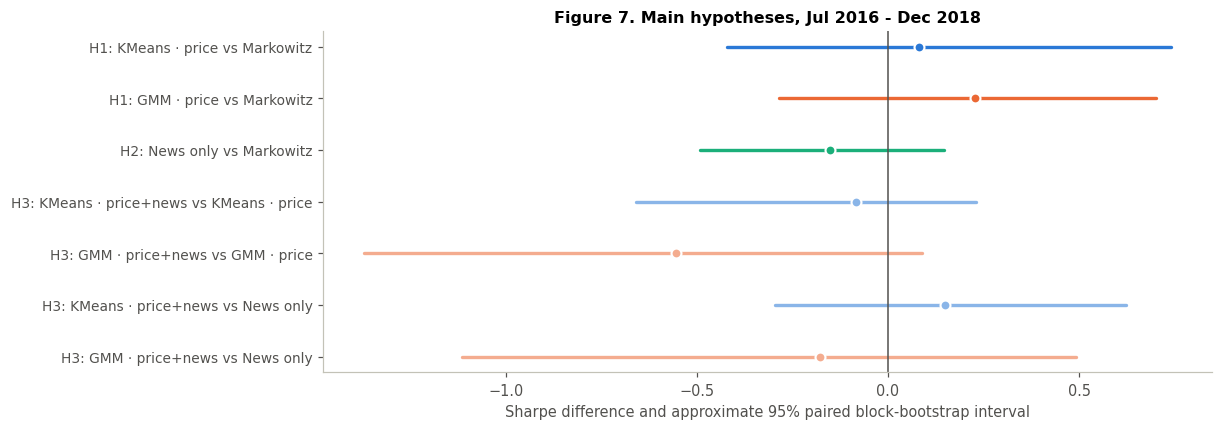

In [20]:
SUMMARY = [("H1", "A", "KMeans · price", "Markowitz"), ("H1", "A", "GMM · price", "Markowitz"),
           ("H2", "A", "News only", "Markowitz"),
           ("H3", "A", "KMeans · price+news", "KMeans · price"), ("H3", "A", "GMM · price+news", "GMM · price"),
           ("H3", "A", "KMeans · price+FRED+news", "KMeans · price+FRED"), ("H3", "A", "GMM · price+FRED+news", "GMM · price+FRED"),
           ("H3", "A", "KMeans · price+news", "News only"), ("H3", "A", "GMM · price+news", "News only"),
           ("FRED", "A", "KMeans · price+FRED", "KMeans · price"), ("FRED", "A", "GMM · price+FRED", "GMM · price"),
           ("H1 + FRED", "A", "KMeans · price+FRED", "Markowitz"), ("H1 + FRED", "A", "GMM · price+FRED", "Markowitz"),
           ("H1", "B", "KMeans · price", "Markowitz"), ("H1", "B", "GMM · price", "Markowitz"),
           ("FRED", "B", "KMeans · price+FRED", "KMeans · price"), ("FRED", "B", "GMM · price+FRED", "GMM · price"),
           ("H1 + FRED", "B", "KMeans · price+FRED", "Markowitz"), ("H1 + FRED", "B", "GMM · price+FRED", "Markowitz")]
rows = []
for h, exp, a, b in SUMMARY:
    c = contrasts(results[exp]["net"], {"x": (a, b)}).iloc[0]
    rows.append({"hypothesis": h, "window": "2016-18" if exp == "A" else "2021-25", "comparison": f"{a}  vs  {b}",
                 "ΔSharpe": c["ΔSharpe"], "95% interval": f"[{c['95% low']:+.2f}, {c['95% high']:+.2f}]",
                 "_low": c["95% low"], "_high": c["95% high"], "_color": style(a)["color"]})
summary_tests = pd.DataFrame(rows)
PRIMARY_ROWS = [0, 1, 2, 3, 4, 7, 8]  # H1, H2, price-based H3 and combined vs sentiment alone
SECONDARY_ROWS = [i for i in summary_tests.index if i not in PRIMARY_ROWS]
for part, ids, title in [("a", PRIMARY_ROWS, "Main hypotheses, Jul 2016 - Dec 2018"),
                         ("b", SECONDARY_ROWS, "FRED extensions and additional-period comparisons")]:
    print(f"Table 10{part}. {title}; first strategy minus second")
    show(summary_tests.loc[ids, ["hypothesis", "window", "comparison", "ΔSharpe", "95% interval"]]
         .set_index(["hypothesis", "window", "comparison"]), "{:+.2f}")

primary_tests = summary_tests.loc[PRIMARY_ROWS]
fig, ax = plt.subplots(figsize=(11, 3.8), layout="constrained")
y = np.arange(len(primary_tests))[::-1]
for yi, (_, r) in zip(y, primary_tests.iterrows()):
    ax.plot([r["_low"], r["_high"]], [yi, yi], color=r["_color"], lw=2.2, solid_capstyle="round")
    ax.plot(r["ΔSharpe"], yi, "o", color=r["_color"], ms=6.5, mec="white", mew=1.4)
ax.axvline(0, color="#52514e", lw=1)
ax.set_yticks(y, [f"{r.hypothesis}: {r.comparison.replace('  vs  ', ' vs ')}" for r in primary_tests.itertuples()], fontsize=9)
ax.set(xlabel="Sharpe difference and approximate 95% paired block-bootstrap interval",
       title="Figure 7. Main hypotheses, Jul 2016 - Dec 2018")
plt.show()


All seven primary intervals in Figure 7 include zero. Across the 19 summary contrasts, two intervals exclude zero: FRED–KMeans exceeds Markowitz (+0.33), while its independently selected news counterpart falls behind it (−0.52), both in A. The shared baseline, multiple comparisons and short sample preclude treating these as independent confirmations. No positive regime increment repeats across both periods. Adding FRED to GMM lowers sample Sharpe in both, although neither interval excludes zero.

## 5. Robustness checks and limitations

### 5.1 Robustness

**Transaction costs.** The same target weights are repriced at 0 and 25 bp.


In [21]:
cost = {}
for exp in EXPERIMENTS:
    for fee in [0, 10, 25]:
        cost[(exp, f"{fee} bp")] = sharpe(pd.DataFrame({s: backtest(w, fee).net for s, w in results[exp]["weights"].items()}))
print("Table 11. Sharpe ratio by cost level")
show(pd.DataFrame(cost).reindex(STRATEGY_ORDER))

Table 11. Sharpe ratio by cost level


A                  B            
                          0 bp 10 bp  25 bp  0 bp 10 bp 25 bp
Equal weight              0.65  0.64   0.63  0.80  0.79  0.78
Markowitz                 0.36  0.35   0.33  1.15  1.14  1.13
KMeans · price            0.45  0.43   0.40  1.05  1.04  1.01
GMM · price               0.60  0.57   0.53  1.12  1.11  1.08
KMeans · price+FRED       0.71  0.68   0.64  1.06  1.04  1.01
GMM · price+FRED          0.47  0.44   0.40  0.90  0.88  0.86
News only                 0.23  0.20   0.15     –     –     –
KMeans · price+news       0.37  0.34   0.30     –     –     –
GMM · price+news          0.05  0.02  -0.03     –     –     –
KMeans · price+FRED+news  0.18  0.16   0.12     –     –     –
GMM · price+FRED+news     0.44  0.41   0.37     –     –     –

Within the tested proportional-fee range, costs have modest effects on Sharpe and do not change the main interpretation. Going from 0 to 25 bp lowers Sharpe ratios by 0.02–0.08, and the larger drops are for the high-turnover regime and sentiment strategies. No difference with Markowitz changes sign, except for KMeans · price+news, whose difference from Markowitz is near zero at every cost level.

**Regime stability and the number of states.** Table 4 showed small, sometimes empty states and seed-sensitive GMMs. Table 12 shows what this means for the portfolios: every regime strategy is rerun with each $k\in\{2,3,4\}$, keeping everything else fixed (\* = the $k$ selected in Table 2).

In [22]:
k_rows, k_paths = {}, {}
for exp, cfg in EXPERIMENTS.items():
    for fs in cfg["feature_sets"]:
        X = FEATURES[fs].loc[:cfg["last"]]
        dev = X.index[X.index <= cfg["model_end"]]
        W_k = allocate({(alg, k): fit_regimes(X, alg, k, dev) for alg in ["KMeans", "GMM"] for k in K_GRID},
                       cfg["dates"], cfg["model_end"])
        for alg in ["KMeans", "GMM"]:
            for k in K_GRID:
                k_paths[(exp, fs, alg, k)] = backtest(W_k[(alg, k)]).net
            k_rows[(exp, fs, alg)] = {f"k={k}": f"{sharpe(k_paths[(exp, fs, alg, k)]):.2f}" + ("*" if k == chosen_k[(exp, alg, fs)] else "")
                                      for k in K_GRID}
            k_rows[(exp, fs, alg)]["Markowitz"] = f"{perf[exp].loc['Markowitz', 'Sharpe']:.2f}"
print("Table 12. Sharpe ratio for each number of states")
display(pd.DataFrame(k_rows).T.rename_axis(["window", "features", "model"]))
matched_net = pd.DataFrame({fs: k_paths[("A", fs, "KMeans", 3)] for fs in ["price+FRED", "price+FRED+news"]})
matched_contrast = contrasts(matched_net, {"KMeans, fixed k=3: add news to price+FRED": ("price+FRED+news", "price+FRED")})
print("Fixed-k sensitivity from Notebook 05 (same six-month paired bootstrap):")
show(matched_contrast, "{:+.3f}")


Table 12. Sharpe ratio for each number of states


k=2    k=3    k=4 Markowitz
window features        model                                
A      price           KMeans   0.28  0.43*   0.69      0.35
                       GMM      0.46   0.56  0.57*      0.35
       price+FRED      KMeans   0.17  0.68*   0.58      0.35
                       GMM      0.44   0.45  0.44*      0.35
       price+news      KMeans   0.14  0.34*   0.31      0.35
                       GMM      0.46   0.47  0.02*      0.35
       price+FRED+news KMeans  0.16*   0.51   0.36      0.35
                       GMM      0.49   0.45  0.41*      0.35
B      price           KMeans   0.95  1.04*   1.23      1.14
                       GMM      1.20   1.21  1.11*      1.14
       price+FRED      KMeans   1.03   0.95  1.04*      1.14
                       GMM      1.12   0.84  0.88*      1.14

Fixed-k sensitivity from Notebook 05 (same six-month paired bootstrap):


,ΔSharpe,95% low,95% high
"KMeans, fixed k=3: add news to price+FRED",-0.168,-0.633,+0.062


Changing $k$ moves some Sharpe ratios by about 0.5. For example, price-only KMeans ranges from 0.28 to 0.69 in A. The selection criteria target clustering structure, so their selected counts need not maximise portfolio Sharpe; picking a different count from this table would use evaluation performance.

**Two distinct FRED–KMeans comparisons.** The main, independently selected pipelines give 0.68 without sentiment ($k=3$) versus 0.16 with sentiment ($k=2$): difference −0.52, interval [−1.18, −0.13]. Holding both at $k=3$, as in Notebook 05, gives 0.68 versus 0.51: difference −0.168, interval [−0.633, +0.062]. The first evaluates the selection procedure with new inputs; the second isolates adding sentiment while holding the state count fixed. Both sample differences are negative, but only the first interval excludes zero. Neither justifies choosing a specification using evaluation Sharpe.

The grid also illustrates period sensitivity: 17 of 24 regime variants exceed Markowitz in A, whereas 9 of 12 fall below it in B. These variants share data and are not independent replications. The sensitivity and sparse states limit confidence in any particular regime specification.

**Bootstrap block length.** Table 13 repeats all 19 summary contrasts with 3-, 6- and 12-month blocks, retaining the primary/secondary grouping.


In [23]:
blocks = {}
for h, exp, a, b in SUMMARY:
    for bl in [3, 6, 12]:
        c = contrasts(results[exp]["net"], {"x": (a, b)}, block=bl).iloc[0]
        blocks.setdefault((h, "2016-18" if exp == "A" else "2021-25", f"{a} vs {b}"), {})[f"{bl}-month blocks"] = \
            f"{c['ΔSharpe']:+.2f} [{c['95% low']:+.2f}, {c['95% high']:+.2f}]"
block_table = pd.DataFrame(blocks).T.rename_axis(["hypothesis", "window", "comparison"])
for part, ids in [("a", PRIMARY_ROWS), ("b", SECONDARY_ROWS)]:
    print(f"Table 13{part}. Sharpe differences and approximate 95% intervals by block length")
    display(block_table.iloc[ids])

Table 13a. Sharpe differences and approximate 95% intervals by block length


3-month blocks  \
hypothesis window  comparison                                                    
H1         2016-18 KMeans · price vs Markowitz            +0.08 [-0.38, +0.69]   
                   GMM · price vs Markowitz               +0.23 [-0.30, +0.86]   
H2         2016-18 News only vs Markowitz                 -0.15 [-0.64, +0.24]   
H3         2016-18 KMeans · price+news vs KMeans · price  -0.08 [-0.62, +0.28]   
                   GMM · price+news vs GMM · price        -0.56 [-1.51, +0.08]   
                   KMeans · price+news vs News only       +0.15 [-0.43, +0.85]   
                   GMM · price+news vs News only          -0.18 [-1.17, +0.67]   

                                                                6-month blocks  \
hypothesis window  comparison                                                    
H1         2016-18 KMeans · price vs Markowitz            +0.08 [-0.42, +0.74]   
                   GMM · price vs Markowitz               +0.23 [-0.29, +0.70]   
H2         2016-18 News only vs Markowitz                 -0.15 [-0.49, +0.15]   
H3         2016-18 KMeans · price+news vs KMeans · price  -0.08 [-0.66, +0.23]   
                   GMM · price+news vs GMM · price        -0.56 [-1.37, +0.09]   
                   KMeans · price+news vs News only       +0.15 [-0.29, +0.62]   
                   GMM · price+news vs News only          -0.18 [-1.11, +0.49]   

                                                               12-month blocks  
hypothesis window  comparison                                                   
H1         2016-18 KMeans · price vs Markowitz            +0.08 [-0.47, +0.76]  
                   GMM · price vs Markowitz               +0.23 [-0.09, +0.53]  
H2         2016-18 News only vs Markowitz                 -0.15 [-0.40, +0.08]  
H3         2016-18 KMeans · price+news vs KMeans · price  -0.08 [-0.64, +0.20]  
                   GMM · price+news vs GMM · price        -0.56 [-1.41, +0.01]  
                   KMeans · price+news vs News only       +0.15 [-0.28, +0.50]  
                   GMM · price+news vs News only          -0.18 [-1.07, +0.51]

Table 13b. Sharpe differences and approximate 95% intervals by block length


3-month blocks  \
hypothesis window  comparison                                                              
H3         2016-18 KMeans · price+FRED+news vs KMeans · price+FRED  -0.52 [-1.23, -0.09]   
                   GMM · price+FRED+news vs GMM · price+FRED        -0.03 [-0.09, +0.01]   
FRED       2016-18 KMeans · price+FRED vs KMeans · price            +0.25 [-0.03, +0.59]   
                   GMM · price+FRED vs GMM · price                  -0.14 [-0.64, +0.23]   
H1 + FRED  2016-18 KMeans · price+FRED vs Markowitz                 +0.33 [+0.06, +0.82]   
                   GMM · price+FRED vs Markowitz                    +0.09 [-0.38, +0.50]   
H1         2021-25 KMeans · price vs Markowitz                      -0.11 [-0.40, +0.11]   
                   GMM · price vs Markowitz                         -0.04 [-0.38, +0.30]   
FRED       2021-25 KMeans · price+FRED vs KMeans · price            +0.00 [-0.18, +0.19]   
                   GMM · price+FRED vs GMM · price                  -0.22 [-0.60, +0.13]   
H1 + FRED  2021-25 KMeans · price+FRED vs Markowitz                 -0.10 [-0.36, +0.09]   
                   GMM · price+FRED vs Markowitz                    -0.26 [-0.58, -0.00]   

                                                                          6-month blocks  \
hypothesis window  comparison                                                              
H3         2016-18 KMeans · price+FRED+news vs KMeans · price+FRED  -0.52 [-1.18, -0.13]   
                   GMM · price+FRED+news vs GMM · price+FRED        -0.03 [-0.08, +0.01]   
FRED       2016-18 KMeans · price+FRED vs KMeans · price            +0.25 [-0.01, +0.55]   
                   GMM · price+FRED vs GMM · price                  -0.14 [-0.67, +0.23]   
H1 + FRED  2016-18 KMeans · price+FRED vs Markowitz                 +0.33 [+0.04, +0.81]   
                   GMM · price+FRED vs Markowitz                    +0.09 [-0.36, +0.43]   
H1         2021-25 KMeans · price vs Markowitz                      -0.11 [-0.40, +0.10]   
                   GMM · price vs Markowitz                         -0.04 [-0.37, +0.29]   
FRED       2021-25 KMeans · price+FRED vs KMeans · price            +0.00 [-0.18, +0.14]   
                   GMM · price+FRED vs GMM · price                  -0.22 [-0.57, +0.08]   
H1 + FRED  2021-25 KMeans · price+FRED vs Markowitz                 -0.10 [-0.37, +0.10]   
                   GMM · price+FRED vs Markowitz                    -0.26 [-0.58, +0.00]   

                                                                         12-month blocks  
hypothesis window  comparison                                                             
H3         2016-18 KMeans · price+FRED+news vs KMeans · price+FRED  -0.52 [-1.19, -0.10]  
                   GMM · price+FRED+news vs GMM · price+FRED        -0.03 [-0.08, +0.01]  
FRED       2016-18 KMeans · price+FRED vs KMeans · price            +0.25 [-0.01, +0.59]  
                   GMM · price+FRED vs GMM · price                  -0.14 [-0.55, +0.18]  
H1 + FRED  2016-18 KMeans · price+FRED vs Markowitz                 +0.33 [+0.03, +0.79]  
                   GMM · price+FRED vs Markowitz                    +0.09 [-0.35, +0.43]  
H1         2021-25 KMeans · price vs Markowitz                      -0.11 [-0.37, +0.07]  
                   GMM · price vs Markowitz                         -0.04 [-0.28, +0.22]  
FRED       2021-25 KMeans · price+FRED vs KMeans · price            +0.00 [-0.16, +0.12]  
                   GMM · price+FRED vs GMM · price                  -0.22 [-0.56, +0.03]  
H1 + FRED  2021-25 KMeans · price+FRED vs Markowitz                 -0.10 [-0.35, +0.09]  
                   GMM · price+FRED vs Markowitz                    -0.26 [-0.55, -0.00]

Block length leaves the primary conclusions unchanged, though some secondary intervals are borderline. The two comparisons that exclude zero with six-month blocks do so for all three lengths. With 3- and 12-month blocks, one more crosses the line: GMM · price+FRED against Markowitz in 2021–2025, whose upper bound moves from +0.00 to just below zero. GMM · price+news against GMM · price comes close with 12-month blocks ([−1.41, +0.01]). Both borderline cases go against the richer model.

**Additional evaluation period, 2021–2025 (H1 and FRED).** The retained news sample stops in 2018, so H2 and H3 cannot be tested here.

Table 14. Additional period (Mar 2021 - Dec 2025, 58 months), net of 10 bp costs


,Sharpe,CAGR,volatility,max drawdown,turnover / month,gold weight,ΔSharpe vs Markowitz [95%]
Equal weight,0.79,13.0%,17.4%,-25.3%,7.3%,20.0%,"-0.35 [-1.09, +0.31]"
Markowitz,1.14,13.7%,11.9%,-17.1%,6.1%,59.7%,
KMeans · price,1.04,13.3%,12.9%,-16.6%,16.3%,56.6%,"-0.11 [-0.40, +0.10]"
GMM · price,1.11,14.5%,13.1%,-19.4%,18.7%,57.9%,"-0.04 [-0.37, +0.29]"
KMeans · price+FRED,1.04,13.4%,12.9%,-16.6%,18.9%,57.1%,"-0.10 [-0.37, +0.10]"
GMM · price+FRED,0.88,10.8%,12.5%,-19.1%,17.3%,54.0%,"-0.26 [-0.58, +0.00]"


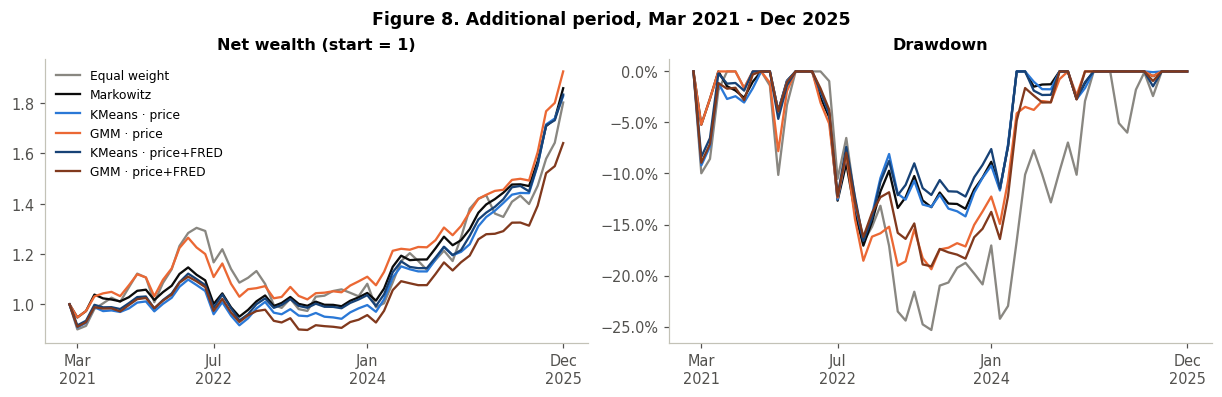

Gross return difference with Markowitz by asset, % per year:


,Brent,US gas,Gold,Silver,Copper,total
Equal weight,+1.2,+3.6,-7.5,+3.4,-0.5,+0.2
KMeans · price,+0.5,-0.9,+0.2,+1.0,-0.9,-0.1
GMM · price,+0.9,-0.0,-0.3,+1.1,-0.6,+1.0
KMeans · price+FRED,+0.6,-0.4,-0.1,+0.3,-0.4,-0.0
GMM · price+FRED,+0.1,-0.5,-1.0,-0.1,-0.8,-2.4


In [24]:
print("Table 14. Additional period (Mar 2021 - Dec 2025, 58 months), net of 10 bp costs")
show(with_contrast("B", list(results["B"]["net"])), **PCT)

net_b = results["B"]["net"]
start = net_b.index[0] - pd.DateOffset(months=1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
for s in net_b:
    wealth = pd.concat([pd.Series({start: 1.0}), (1 + net_b[s]).cumprod()])
    axes[0].plot(wealth.index, wealth, lw=1.5, label=s, **style(s))
    axes[1].plot(wealth.index, wealth / wealth.cummax() - 1, lw=1.5, **style(s))
axes[0].set(title="Net wealth (start = 1)")
axes[1].set(title="Drawdown")
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].legend(fontsize=8)
for ax in axes:
    ax.set_xticks(pd.to_datetime(["2021-03-01", "2022-07-01", "2024-01-01", "2025-12-01"]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
fig.suptitle("Figure 8. Additional period, Mar 2021 - Dec 2025", fontweight="bold")
plt.show()
print("Gross return difference with Markowitz by asset, % per year:")
show(attribution("B", [s for s in net_b if s != "Markowitz"]), "{:+.1f}")

Markowitz has Sharpe 1.14 in B, against 0.79 for equal weight and 0.88–1.11 for the four regime strategies. Equal weight has the largest drawdown (−25.3%); the two KMeans versions improve on Markowitz's −17.1% by about half a percentage point. Regime strategies trade more (16–19% per month versus 6%).

Mean gold weights are 59.7% for Markowitz and 54.0–57.9% for the regime strategies; they are not always at the cap. The asset attribution accounts for the FRED–GMM gross shortfall of 2.4 percentage points a year: approximately 1.0 from gold, 0.8 from copper, 0.5 from gas and 0.1 from silver, partly offset by Brent. This is an arithmetic decomposition, not evidence that gold alone caused underperformance. The period reproduces Notebook 03's returns to numerical precision and does not confirm the positive H1 differences seen in A.

**Other checks.** (i) A zero sentiment threshold instead of the development median. (ii) Price-only regimes in B trained from January 2001, the longer history used in Notebooks 01–02.


In [25]:
W0 = allocate({"zero": pd.DataFrame(np.eye(2)[(sentiment > 0).astype(int)], index=sentiment.index)},
              EXPERIMENTS["A"]["dates"], EXPERIMENTS["A"]["model_end"])
print(f"News only with a zero threshold: Sharpe {sharpe(backtest(W0['zero']).net):.2f} "
      f"(median threshold {perf['A'].loc['News only', 'Sharpe']:.2f}, Markowitz {perf['A'].loc['Markowitz', 'Sharpe']:.2f})")
cfg = EXPERIMENTS["B"]
X01 = price_feat.dropna()
k01, _ = select_k(X01, X01.index[X01.index <= cfg["train_end"]],
                  X01.index[(X01.index > cfg["train_end"]) & (X01.index <= cfg["model_end"])])
W01 = allocate({alg: fit_regimes(X01, alg, k01[alg], X01.index[X01.index <= cfg["model_end"]]) for alg in ["KMeans", "GMM"]},
               cfg["dates"], cfg["model_end"])
print(f"2021-25, price-only regimes trained from Jan 2001 (k = {k01}): "
      + ", ".join(f"{s} {sharpe(backtest(W01[s]).net):.2f}" for s in ["Markowitz", "KMeans", "GMM"]))

News only with a zero threshold: Sharpe 0.32 (median threshold 0.20, Markowitz 0.35)


2021-25, price-only regimes trained from Jan 2001 (k = {'KMeans': 3, 'GMM': 4}): Markowitz 1.14, KMeans 1.05, GMM 1.12


With a zero threshold, news-only Sharpe is 0.32, versus 0.20 with the median threshold and 0.35 for Markowitz. Extending price-only model fitting back to 2001 gives 1.05 (KMeans) and 1.12 (GMM) in B, versus 1.04 and 1.11 on the common sample. Neither check reverses the main interpretation.

### 5.2 Methodological limitations

**Point-in-time availability.** The inputs are recent snapshots. In particular, the dollar-index methodology behind `DTWEXBGS` was introduced on 4 February 2019 and back-filled to 2006 ([Federal Reserve implementation notice](https://www.federalreserve.gov/econres/notes/feds-notes/revisions-to-the-federal-reserve-dollar-indexes-20190115.html)). It was unavailable in that form during A. World Bank and FRED revisions, retrospective news annotations and missing collection timestamps also prevent a fully point-in-time interpretation. The lag addresses assumed publication delays, not these vintage issues. Their effects on estimated performance and strategy rankings can be positive or negative; they neither validate nor strengthen a negative finding.

**Price proxies and costs.** Monthly-average benchmark changes omit futures roll yield, collateral returns and executable prices. Averaging changes volatility and dependence, while the fees are stylised rather than measured trading costs. Common inputs make comparisons internally consistent, but do not guarantee that rankings would survive on investable returns. The drift calculation is also synthetic accounting, not evidence of historically executable rebalances.

**Sentiment scope.** The index covers gold alone and predominantly describes past moves. Invalid dates, changing coverage and the redistribution's categorical-label construction may affect it. The conclusions concern this index and allocation rule, not financial news in general; weak linear correlations do not rule out nonlinear or risk-related information.

**Uncertainty and research selection.** Thirty and 58 monthly observations provide limited precision. The IID standard-error benchmark understates the complexity of dependent, non-normal returns; the block intervals preserve only some dependence, use few blocks and omit estimation and model-selection uncertainty. State count and GMM initialisation matter. Both windows were examined earlier in the project, and none of the many comparisons is adjusted for research selection or multiplicity. Chronological evaluation on frozen snapshots therefore supports exploratory conclusions, not an untouched holdout claim.

## 6. Discussion and conclusion

**Market regimes.** KMeans and GMM identify recognisable price environments, but separation is weak, occupancy uneven and some partitions sensitive to initialisation. Price-based conditioning raises sample Sharpe relative to Markowitz in A and lowers it in B; all four paired intervals include zero. Gold concentration and regularisation limit, but do not eliminate, allocation changes.

**News sentiment.** Sentiment alone underperforms Markowitz in A. Adding it to independently selected regime pipelines lowers sample Sharpe in all four comparisons. The largest decline, for FRED–KMeans, also changes $k$; the matched-$k=3$ comparison is smaller and inconclusive. Neither comparison establishes an improvement, and neither identifies why sentiment underperforms. FRED likewise provides no repeatable allocation gain.

**Answer to the research question.** This study does not establish that regime detection or this gold-news sentiment index improves dynamic commodity allocation under the stated design. It also cannot rule out useful effects outside this short sample, feature definition and portfolio rule. The consistent operational result is greater turnover for conditioned portfolios; performance rankings depend on the period and model specification.

A stronger test would use investable commodity returns, historically available predictors and new evaluation dates under a protocol fixed before inspecting outcomes. Broader or forward-oriented news coverage is a possible extension, not a benefit demonstrated by these results.

## 7. References and reproducibility

**References**

* Lo, A. W. (2002). [The statistics of Sharpe ratios](https://doi.org/10.2469/faj.v58.n4.2453). *Financial Analysts Journal*, 58(4), 36–52.
* Sinha, A. and Khandait, T. (2020). Impact of news on the commodity market: dataset and results. [arXiv:2009.04202](https://arxiv.org/abs/2009.04202). Data: [SaguaroCapital/sentiment-analysis-in-commodity-market-gold](https://huggingface.co/datasets/SaguaroCapital/sentiment-analysis-in-commodity-market-gold), revision `4423810`.
* von Beschwitz, B., Collins, C. G. and Datta, D. D. (2019). [Revisions to the Federal Reserve dollar indexes](https://www.federalreserve.gov/econres/notes/feds-notes/revisions-to-the-federal-reserve-dollar-indexes-20190115.html). FEDS Notes.
* Working, H. (1960). Note on the correlation of first differences of averages in a random chain. *Econometrica*, 28(4), 916–918.
* World Bank, [Commodity Markets (Pink Sheet)](https://www.worldbank.org/en/research/commodity-markets). FRED, Federal Reserve Bank of St. Louis: [VIXCLS](https://fred.stlouisfed.org/series/VIXCLS), [DTWEXBGS](https://fred.stlouisfed.org/series/DTWEXBGS), [DGS10](https://fred.stlouisfed.org/series/DGS10), [DGS2](https://fred.stlouisfed.org/series/DGS2).
* Champonnois, S. (2026). [*Machine-learning for Portfolio Management and Trading: An Introduction with Scikit-Learn*](https://github.com/schampon/skfin/blob/master/book/book.pdf), 15 September edition, Chapters 3–4 and Appendix 30; accompanying course notebooks ([skfin](https://github.com/schampon/skfin/tree/master/nbs)): `10_Mean_variance_estimators`, `11_Backtesting`, `30_Transaction_cost`, `41_Timing_backtest_with_learning`, `46_Text_processing`.

**Reproducibility.** All data are retrieved by the notebook itself. Files are read from the project repository when the notebook is run inside it, and otherwise downloaded from pinned revisions: GitHub commit `3eaa7f3` for the World Bank and FRED snapshots (retrieved 7 November 2026) and Hugging Face revision `4423810` for the news. Every file is checked against its SHA-256 hash. Random seeds are fixed (42 for models and bootstrap). Versions used for the saved run: Python 3.12, numpy 2.4.4, pandas 2.3.3, scipy 1.17.1, scikit-learn 1.9.0, matplotlib 3.10.9, openpyxl 3.1.5, pyarrow 25.0.1, requests 2.34.2.


In a fresh Python 3.12 Jupyter kernel, install dependencies once if needed, then restart and run all cells:

```python
%pip install numpy==2.4.4 pandas==2.3.3 scipy==1.17.1 scikit-learn==1.9.0 matplotlib==3.10.9 openpyxl==3.1.5 pyarrow==25.0.1 requests==2.34.2 ipython==8.30.0
```

No source notebook is executed or imported. Downloads are read in memory and verified before parsing; no generated files are needed to reproduce the submission. Numerical results may differ across package versions or numerical libraries, so the recorded environment and seeds should be retained.
